In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/abdelmdz/uk-dale/ukdale.h5


In [2]:
# ============================================================================
# CELL 1: Installation et imports - FRIDGE (INDÉPENDANT)
# ============================================================================

!pip install joblib seaborn scikit-learn -q

import os
import warnings
import logging
import glob
import gc
import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import h5py

os.environ['HDF5_PLUGIN_PATH'] = '/tmp/hdf5_plugins'
os.makedirs('/tmp/hdf5_plugins', exist_ok=True)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['CUDA_DEVICE_ORDER'] = 'PCI_BUS_ID'

warnings.filterwarnings('ignore')
logging.getLogger('tensorflow').setLevel(logging.ERROR)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from scipy.signal import find_peaks

print('='*60)
print('FRIDGE NILM - Version complète (50 epochs)')
print('='*60)
print(f'TensorFlow: {tf.__version__}')
print(f'GPU: {tf.config.list_physical_devices("GPU")}')

E0000 00:00:1776627498.281292      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1776627498.341737      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1776627498.813976      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776627498.814014      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776627498.814016      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776627498.814018      24 computation_placer.cc:177] computation placer already registered. Please check linka

FRIDGE NILM - Version complète (50 epochs)
TensorFlow: 2.19.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
# ============================================================================
# CELL 2 (Version simplifiée): Configuration FRIDGE - sans house_5
# ============================================================================

class Config:
    """Configuration spécifique pour le FRIDGE - Version simplifiée"""
    
    # Paramètres du modèle
    WINDOW_SIZE = 599
    BATCH_SIZE = 256
    EPOCHS = 50
    LR = 1e-3
    VAL_SPLIT = 0.15
    SEED = 42
    FREQ = '6s'
    
    # Limites mémoire
    MAX_TRAIN_SAMPLES = 500_000
    MAX_TEST_SAMPLES = 100_000
    
    H5_PATH = None
    
    # PARAMÈTRES FRIDGE
    FRIDGE = {
        'name': 'Fridge',
        'threshold': 0,
        'max_power': 800,
        'mean_on': 150,
        'std_on': 80,
        'color': '#2E86AB',
        'window_minutes': 90
    }
    
    # Configuration des maisons (sans house_5 pour éviter l'erreur)
    UKDALE_HOUSES = {
        'house_1': {
            'name': 'UKDALE-1',
            'house_id': 1,
            'fridge_meter': 12,
            'train': ('2013-04-01', '2014-03-31'),
            'test': ('2014-04-01', '2014-05-01'),
        },
        'house_2': {
            'name': 'UKDALE-2',
            'house_id': 2,
            'fridge_meter': 14,
            'test': ('2013-07-28', '2013-08-11'),
        },
    }
    
    @classmethod
    def get_meter(cls, house_id=1):
        for house_key, config in cls.UKDALE_HOUSES.items():
            if config['house_id'] == house_id:
                return f"meter{config['fridge_meter']}"
        return "meter12"
    
    @classmethod
    def get_threshold(cls):
        return cls.FRIDGE['threshold']


# Trouver le fichier H5
h5_files = glob.glob('/kaggle/input/**/*.h5', recursive=True)
if h5_files:
    Config.H5_PATH = h5_files[0]
    print(f"✅ Fichier trouvé: {Config.H5_PATH}")
else:
    print("❌ Aucun fichier .h5 trouvé!")

tf.random.set_seed(Config.SEED)
np.random.seed(Config.SEED)

print("="*60)
print("CONFIGURATION FRIDGE (Version simplifiée)")
print("="*60)
print(f"Appareil: {Config.FRIDGE['name']}")
print(f"Building 1 (train): {Config.get_meter(1)}")
print(f"Building 2 (test):  {Config.get_meter(2)}")
print(f"Seuil: PAS DE SEUIL (fonctionnement continu)")
print(f"Window size: {Config.WINDOW_SIZE} pts = {Config.WINDOW_SIZE*6/60:.0f} min")

✅ Fichier trouvé: /kaggle/input/datasets/abdelmdz/uk-dale/ukdale.h5
CONFIGURATION FRIDGE (Version simplifiée)
Appareil: Fridge
Building 1 (train): meter12
Building 2 (test):  meter14
Seuil: PAS DE SEUIL (fonctionnement continu)
Window size: 599 pts = 60 min


In [4]:
# ============================================================================
# CELL 3 (Corrigée): Chargeur de données UK-DALE avec gestion d'erreurs
# ============================================================================

class UKDALEDataLoader:
    """Chargeur de données UK-DALE spécialisé FRIDGE"""
    
    def __init__(self, h5_path):
        self.h5_path = h5_path
        self._cache = {}
    
    def read_meter(self, building, meter, max_points=None):
        cache_key = f"b{building}_{meter}"
        if cache_key in self._cache:
            return self._cache[cache_key]
        
        try:
            key = f'building{building}/elec/{meter}'
            s = pd.read_hdf(self.h5_path, key=key)
            if isinstance(s, pd.DataFrame):
                s = s.iloc[:, 0]
            s = s.astype(np.float32)
            s = s[~s.index.duplicated(keep='first')]
            s = s.sort_index()
            if max_points and len(s) > max_points:
                s = s.iloc[:max_points]
            self._cache[cache_key] = s
            return s
        except Exception:
            return None
    
    def _to_tz_aware(self, date_str, tz='Europe/London'):
        if date_str is None:
            return None
        dt = pd.Timestamp(date_str)
        if dt.tz is None:
            dt = dt.tz_localize(tz)
        return dt
    
    def load_house_data(self, house_key, mode='train', max_samples=None):
        if house_key not in Config.UKDALE_HOUSES:
            raise ValueError(f"Maison {house_key} non trouvée")
        
        house_config = Config.UKDALE_HOUSES[house_key]
        house_id = house_config['house_id']
        fridge_meter = f"meter{house_config['fridge_meter']}"
        
        if mode == 'train':
            if 'train' not in house_config:
                return None
            start_date = self._to_tz_aware(house_config['train'][0])
            end_date = self._to_tz_aware(house_config['train'][1])
        else:
            if 'test' not in house_config:
                return None
            start_date = self._to_tz_aware(house_config['test'][0])
            end_date = self._to_tz_aware(house_config['test'][1])
        
        print(f"\n{'='*50}")
        print(f"{mode.upper()}: {house_config['name']}")
        print(f"Période: {start_date.date()} → {end_date.date()}")
        print(f"FRIDGE compteur: {fridge_meter}")
        print(f"{'='*50}")
        
        all_meters = {}
        monitored_meters = []
        
        # Fridge - avec vérification
        s = self.read_meter(house_id, fridge_meter)
        if s is not None and len(s) > 0:
            all_meters[fridge_meter] = s
            monitored_meters.append(fridge_meter)
            print(f"✅ {fridge_meter}: {len(s):,} points")
        else:
            print(f"❌ {fridge_meter} non trouvé ou vide!")
            return None
        
        # Autres compteurs pour la somme (mains)
        for i in range(1, 30):
            meter = f"meter{i}"
            if meter != fridge_meter and meter not in all_meters:
                s = self.read_meter(house_id, meter)
                if s is not None and len(s) > 0:
                    all_meters[meter] = s
                    monitored_meters.append(meter)
        
        print(f"✅ {len(all_meters)} compteurs chargés")
        
        # Grille temporelle
        start_dates = [s.index.min() for s in all_meters.values() if len(s) > 0]
        end_dates = [s.index.max() for s in all_meters.values() if len(s) > 0]
        
        if not start_dates or not end_dates:
            print("❌ Pas de données valides!")
            return None
            
        common_start = max(start_dates)
        common_end = min(end_dates)
        
        grid_start = max(common_start, start_date)
        grid_end = min(common_end, end_date)
        
        # Vérifier que les dates sont valides
        if grid_start >= grid_end:
            print(f"⚠️ Pas de données dans la période sélectionnée!")
            return None
            
        grid = pd.date_range(grid_start, grid_end, freq=Config.FREQ, tz='Europe/London')
        
        print(f"Grille: {len(grid):,} points")
        
        # DataFrame
        df_dict = {}
        for meter, series in all_meters.items():
            df_dict[meter] = series.reindex(grid, method='nearest', tolerance=Config.FREQ).fillna(0)
        
        df = pd.DataFrame(df_dict)
        
        if max_samples and len(df) > max_samples:
            df = df.iloc[:max_samples]
        
        # Statistiques fridge - avec vérification
        fridge_power = df[fridge_meter].values
        
        if len(fridge_power) == 0:
            print(f"❌ Pas de données pour {fridge_meter} après rééchantillonnage!")
            return None
        
        print(f"\n📊 FRIDGE ({fridge_meter}) - {mode}:")
        print(f"   Max: {fridge_power.max():.0f} W")
        print(f"   Moy: {fridge_power.mean():.1f} W")
        print(f"   Points: {len(fridge_power):,}")
        
        return {
            'name': house_config['name'],
            'house_id': house_id,
            'house_key': house_key,
            'df': df,
            'fridge_meter': fridge_meter,
            'monitored_meters': monitored_meters,
        }
    
    def clear_cache(self):
        self._cache.clear()
        gc.collect()


if Config.H5_PATH and os.path.exists(Config.H5_PATH):
    loader = UKDALEDataLoader(Config.H5_PATH)
    print("✅ Chargeur UK-DALE initialisé (version corrigée)")
else:
    loader = None

✅ Chargeur UK-DALE initialisé (version corrigée)


In [5]:
# ============================================================================
# CELL 4 (Corrigée): Chargement des données avec gestion d'erreurs
# ============================================================================

print("\n" + "="*60)
print("CHARGEMENT DES DONNÉES FRIDGE")
print("="*60)

if loader is None:
    print("❌ Chargeur non disponible")
    DATA_TRAIN = None
    DATA_TEST = None
    DATA_TEST_HOUSE5 = None
else:
    print("\n📚 Données d'entraînement (house_1):")
    DATA_TRAIN = loader.load_house_data('house_1', mode='train', max_samples=Config.MAX_TRAIN_SAMPLES)
    
    print("\n🔬 Données de test (house_2):")
    try:
        DATA_TEST = loader.load_house_data('house_2', mode='test', max_samples=Config.MAX_TEST_SAMPLES)
    except Exception as e:
        print(f"  ⚠️ Erreur chargement house_2: {e}")
        DATA_TEST = None
    
    print("\n🔬 Données de test (house_5):")
    try:
        DATA_TEST_HOUSE5 = loader.load_house_data('house_5', mode='test', max_samples=Config.MAX_TEST_SAMPLES)
    except Exception as e:
        print(f"  ⚠️ Erreur chargement house_5: {e}")
        DATA_TEST_HOUSE5 = None
    
    if DATA_TRAIN:
        print(f"\n✅ Données prêtes:")
        print(f"   Train (house_1): {DATA_TRAIN['df'].shape}")
        if DATA_TEST:
            print(f"   Test (house_2):  {DATA_TEST['df'].shape}")
        if DATA_TEST_HOUSE5:
            print(f"   Test (house_5):  {DATA_TEST_HOUSE5['df'].shape}")

if DATA_TRAIN is not None:
    print("\n💾 Variables disponibles: DATA_TRAIN")
    if DATA_TEST:
        print("                 DATA_TEST")
    if DATA_TEST_HOUSE5:
        print("                 DATA_TEST_HOUSE5")


CHARGEMENT DES DONNÉES FRIDGE

📚 Données d'entraînement (house_1):

TRAIN: UKDALE-1
Période: 2013-04-01 → 2014-03-31
FRIDGE compteur: meter12
✅ meter12: 19,381,298 points
✅ 29 compteurs chargés
Grille: 2,946,998 points

📊 FRIDGE (meter12) - train:
   Max: 1902 W
   Moy: 35.9 W
   Points: 500,000

🔬 Données de test (house_2):

TEST: UKDALE-2
Période: 2013-07-28 → 2013-08-11
FRIDGE compteur: meter14
✅ meter14: 1,687,285 points
✅ 20 compteurs chargés
Grille: 201,601 points

📊 FRIDGE (meter14) - test:
   Max: 1283 W
   Moy: 57.6 W
   Points: 100,000

🔬 Données de test (house_5):
  ⚠️ Erreur chargement house_5: Maison house_5 non trouvée

✅ Données prêtes:
   Train (house_1): (500000, 29)
   Test (house_2):  (100000, 20)

💾 Variables disponibles: DATA_TRAIN
                 DATA_TEST


In [6]:
# ============================================================================
# CELL 5: Fonctions de fenêtrage et métriques NILM (INDÉPENDANT)
# ============================================================================

def create_windows(data, window_size=Config.WINDOW_SIZE, target_type='point'):
    """Crée des fenêtres glissantes"""
    values = data.values if isinstance(data, pd.Series) else np.array(data)
    values = values.astype(np.float32)
    
    pad = window_size // 2
    values_padded = np.pad(values, (pad, pad), 'constant', constant_values=0)
    
    X = np.array([
        values_padded[i:i + window_size]
        for i in range(len(values))
    ], dtype=np.float32)
    X = X[..., np.newaxis]
    
    if target_type == 'point':
        y = values
    else:
        y = np.array([
            values_padded[i:i + window_size]
            for i in range(len(values))
        ], dtype=np.float32)
    
    return X, y


class NILMMetrics:
    """Métriques NILM - Version sans seuil pour fridge"""
    
    @staticmethod
    def estimation_accuracy(y_true, y_pred):
        numerator = np.sum(np.abs(y_true - y_pred))
        denominator = 2 * np.sum(y_true)
        if denominator == 0:
            return 1.0 if numerator == 0 else 0.0
        return float(np.clip(1 - numerator / denominator, 0, 1))
    
    @staticmethod
    def compute_all(y_true, y_pred):
        """Calcule les métriques SANS seuil"""
        ea = NILMMetrics.estimation_accuracy(y_true, y_pred)
        rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
        mae = np.mean(np.abs(y_true - y_pred))
        corr = np.corrcoef(y_true, y_pred)[0, 1] if y_true.std() > 0 else 0
        
        return {'ea': ea, 'rmse': rmse, 'mae': mae, 'corr': corr}


print(f"✅ create_windows() — window_size={Config.WINDOW_SIZE} pts = {Config.WINDOW_SIZE*6/60:.0f} min")
print("✅ NILMMetrics défini (sans seuil)")

✅ create_windows() — window_size=599 pts = 60 min
✅ NILMMetrics défini (sans seuil)


In [7]:
# ============================================================================
# CELL 6: Architectures CNN (INDÉPENDANT)
# ============================================================================

def create_seq2point(window_size=Config.WINDOW_SIZE, l2_reg=1e-4):
    """Modèle Seq2Point CNN"""
    inputs = keras.Input(shape=(window_size, 1), name='mains_input')
    
    x = layers.Conv1D(30, 10, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(30, 8, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(40, 6, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(50, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(50, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(1024, activation='relu',
                     kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='linear', name='power_output')(x)
    
    return keras.Model(inputs=inputs, outputs=outputs, name='seq2point')


def create_seq2seq(window_size=Config.WINDOW_SIZE, l2_reg=1e-4):
    """Modèle Seq2Seq CNN"""
    inputs = keras.Input(shape=(window_size, 1), name='mains_input')
    
    x = layers.Conv1D(30, 10, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(30, 8, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(40, 6, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(50, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(50, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(1024, activation='relu',
                     kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(window_size, activation='linear', name='seq_output')(x)
    
    return keras.Model(inputs=inputs, outputs=outputs, name='seq2seq')


s2p = create_seq2point()
s2s = create_seq2seq()

print(f"\n{'='*50}")
print("Architectures CNN - FRIDGE")
print(f"{'='*50}")
print(f"Seq2Point: {s2p.count_params():,} paramètres")
print(f"Seq2Seq:   {s2s.count_params():,} paramètres")

I0000 00:00:1776627649.359030      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1776627649.365429      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



Architectures CNN - FRIDGE
Seq2Point: 30,709,049 paramètres
Seq2Seq:   31,321,999 paramètres


In [8]:
# ============================================================================
# CELL 7: Fonctions d'entraînement et prédiction (INDÉPENDANT)
# ============================================================================

def train_fridge(train_data, model_type='seq2point', epochs=Config.EPOCHS):
    """Entraîne le modèle fridge"""
    
    if train_data is None:
        print("❌ Données d'entraînement non disponibles")
        return None
    
    df = train_data['df']
    fridge_meter = train_data['fridge_meter']
    
    if fridge_meter not in df.columns:
        print(f"❌ {fridge_meter} non trouvé!")
        return None
    
    train_mains = df[train_data['monitored_meters']].sum(axis=1).values
    train_fridge = df[fridge_meter].values
    
    print("\n" + "="*60)
    print(f"🚀 ENTRAÎNEMENT FRIDGE - {model_type.upper()} ({epochs} epochs)")
    print("="*60)
    print(f"Compteur: {fridge_meter}")
    print(f"Window: {Config.WINDOW_SIZE} pts ({Config.WINDOW_SIZE*6/60:.0f} min)")
    print(f"Epochs: {epochs}")
    print(f"\n📊 Statistiques entraînement:")
    print(f"   Mains - moy={train_mains.mean():.1f}W, max={train_mains.max():.0f}W")
    print(f"   Fridge - moy={train_fridge.mean():.1f}W, max={train_fridge.max():.0f}W")
    
    # Normalisation
    mains_scaler = StandardScaler()
    fridge_scaler = StandardScaler()
    
    mains_norm = mains_scaler.fit_transform(train_mains.reshape(-1, 1)).flatten()
    fridge_norm = fridge_scaler.fit_transform(train_fridge.reshape(-1, 1)).flatten()
    
    # Fenêtres
    X, _ = create_windows(mains_norm, target_type='point')
    n = min(len(X), len(fridge_norm))
    X = X[:n]
    
    if model_type == 'seq2point':
        y = fridge_norm[:n]
    else:
        pad = Config.WINDOW_SIZE // 2
        padded = np.pad(fridge_norm, (pad, pad), 'constant')
        y = np.array([padded[i:i + Config.WINDOW_SIZE] for i in range(n)], dtype=np.float32)
    
    # Split
    val_size = int(Config.VAL_SPLIT * n)
    X_train, X_val = X[:-val_size], X[-val_size:]
    y_train, y_val = y[:-val_size], y[-val_size:]
    
    print(f"\n  Train: {len(X_train):,} | Val: {len(X_val):,}")
    
    # Modèle
    model = create_seq2point() if model_type == 'seq2point' else create_seq2seq()
    model.compile(optimizer=keras.optimizers.Adam(Config.LR), loss='mse', metrics=['mae'])
    
    # Callbacks
    checkpoint_path = f'fridge_{model_type}.keras'
    callbacks_list = [
        callbacks.ModelCheckpoint(checkpoint_path, monitor='val_loss', save_best_only=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1),
        callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1)
    ]
    
    # Entraînement
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=Config.BATCH_SIZE,
        callbacks=callbacks_list,
        verbose=1
    )
    
    # Charger le meilleur modèle
    if os.path.exists(checkpoint_path):
        model = keras.models.load_model(checkpoint_path)
        print(f"\n✅ Meilleur modèle chargé: {checkpoint_path}")
    
    return {
        'model': model,
        'mains_scaler': mains_scaler,
        'fridge_scaler': fridge_scaler,
        'history': history.history,
        'best_epoch': np.argmin(history.history['val_loss']) + 1
    }


def predict_fridge(mains_series, model_info, model_type='seq2point'):
    """Prédiction pour le fridge"""
    
    mains_norm = model_info['mains_scaler'].transform(mains_series.values.reshape(-1, 1)).flatten()
    X, _ = create_windows(mains_norm, target_type='point')
    
    predictions = []
    batch_size = 512
    
    for i in range(0, len(X), batch_size):
        batch = X[i:i + batch_size]
        pred = model_info['model'].predict(batch, verbose=0)
        
        if model_type == 'seq2point':
            predictions.append(pred.flatten())
        else:
            mid = Config.WINDOW_SIZE // 2
            predictions.append(pred[:, mid])
    
    pred_flat = np.concatenate(predictions)
    
    n = len(mains_series)
    if len(pred_flat) > n:
        pred_flat = pred_flat[:n]
    elif len(pred_flat) < n:
        pred_flat = np.pad(pred_flat, (0, n - len(pred_flat)), 'edge')
    
    return model_info['fridge_scaler'].inverse_transform(pred_flat.reshape(-1, 1)).flatten()


print("✅ train_fridge() défini")
print("✅ predict_fridge() défini")

✅ train_fridge() défini
✅ predict_fridge() défini


In [9]:
# ============================================================================
# CELL 8: Entraînement Seq2Point et Seq2Seq (INDÉPENDANT)
# ============================================================================

print("\n" + "="*60)
print("ENTRAÎNEMENT FRIDGE (50 EPOCHS)")
print("="*60)

if DATA_TRAIN is None:
    print("❌ Données d'entraînement non disponibles")
    fridge_models = None
else:
    fridge_models = {}
    
    # Entraînement Seq2Point
    print("\n" + "▶"*30)
    print("ENTRAÎNEMENT SEQ2POINT")
    print("▶"*30)
    fridge_models['seq2point'] = train_fridge(DATA_TRAIN, 'seq2point', epochs=Config.EPOCHS)
    
    # Entraînement Seq2Seq
    print("\n" + "▶"*30)
    print("ENTRAÎNEMENT SEQ2SEQ")
    print("▶"*30)
    fridge_models['seq2seq'] = train_fridge(DATA_TRAIN, 'seq2seq', epochs=Config.EPOCHS)
    
    print("\n" + "="*60)
    print("✅ ENTRAÎNEMENT TERMINÉ")
    print("="*60)
    if fridge_models['seq2point']:
        print(f"Seq2Point - Meilleure epoch: {fridge_models['seq2point']['best_epoch']}")
    if fridge_models['seq2seq']:
        print(f"Seq2Seq   - Meilleure epoch: {fridge_models['seq2seq']['best_epoch']}")


ENTRAÎNEMENT FRIDGE (50 EPOCHS)

▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶
ENTRAÎNEMENT SEQ2POINT
▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶

🚀 ENTRAÎNEMENT FRIDGE - SEQ2POINT (50 epochs)
Compteur: meter12
Window: 599 pts (60 min)
Epochs: 50

📊 Statistiques entraînement:
   Mains - moy=648.5W, max=12723W
   Fridge - moy=35.9W, max=1902W

  Train: 425,000 | Val: 75,000
Epoch 1/50


I0000 00:00:1776627658.087222      80 service.cc:152] XLA service 0x7efa1c002970 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1776627658.087255      80 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1776627658.087259      80 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1776627658.862456      80 cuda_dnn.cc:529] Loaded cuDNN version 91002


   3/1661 ━━━━━━━━━━━━━━━━━━━━ 1:46 64ms/step - loss: 142.6560 - mae: 6.3816

I0000 00:00:1776627667.311849      80 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1661/1661 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 11.1992 - mae: 1.2818
Epoch 1: val_loss improved from inf to 1.14280, saving model to fridge_seq2point.keras
1661/1661 ━━━━━━━━━━━━━━━━━━━━ 100s 52ms/step - loss: 11.1941 - mae: 1.2815 - val_loss: 1.1428 - val_mae: 0.6707 - learning_rate: 0.0010
Epoch 2/50
1660/1661 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.8217 - mae: 0.4467
Epoch 2: val_loss improved from 1.14280 to 1.05715, saving model to fridge_seq2point.keras
1661/1661 ━━━━━━━━━━━━━━━━━━━━ 86s 52ms/step - loss: 0.8217 - mae: 0.4467 - val_loss: 1.0571 - val_mae: 0.5673 - learning_rate: 0.0010
Epoch 3/50
1660/1661 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.8028 - mae: 0.4069
Epoch 3: val_loss improved from 1.05715 to 0.92728, saving model to fridge_seq2point.keras
1661/1661 ━━━━━━━━━━━━━━━━━━━━ 86s 52ms/step - loss: 0.8028 - mae: 0.4069 - val_loss: 0.9273 - val_mae: 0.4443 - learning_rate: 0.0010
Epoch 4/50
1660/1661 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.8122 - mae: 0.389

In [10]:
# ============================================================================
# CELL 9: Évaluation sur house_2 (INDÉPENDANT)
# ============================================================================

def evaluate_fridge(test_data, model_info, model_type='seq2point'):
    """Évalue le modèle fridge sur les données de test"""
    
    if test_data is None:
        print("❌ Données de test non disponibles")
        return None
    
    df = test_data['df']
    fridge_meter = test_data['fridge_meter']
    
    if fridge_meter not in df.columns:
        print(f"❌ {fridge_meter} non trouvé!")
        return None
    
    true_vals = df[fridge_meter].values
    mains_vals = df[test_data['monitored_meters']].sum(axis=1).values
    
    n = min(len(true_vals), Config.MAX_TEST_SAMPLES)
    true_a = true_vals[:n]
    mains_s = pd.Series(mains_vals[:n])
    
    pred = predict_fridge(mains_s, model_info, model_type)
    pred = np.clip(pred, 0, None)
    
    min_len = min(len(true_a), len(pred))
    metrics = NILMMetrics.compute_all(true_a[:min_len], pred[:min_len])
    
    return metrics, pred[:min_len], true_a[:min_len]


if fridge_models and DATA_TEST:
    print("\n" + "="*60)
    print(f"ÉVALUATION FRIDGE - {DATA_TEST['name']} (50 epochs)")
    print("="*60)
    
    for model_type, model_info in fridge_models.items():
        if model_info is None:
            continue
        metrics, pred, true_vals = evaluate_fridge(DATA_TEST, model_info, model_type)
        
        print(f"\n📊 {model_type.upper()} (50 epochs):")
        print(f"   EA = {metrics['ea']:.4f}")
        print(f"   RMSE = {metrics['rmse']:.1f} W")
        print(f"   MAE = {metrics['mae']:.1f} W")
        print(f"   Corr = {metrics['corr']:.4f}")
        
        # Sauvegarder
        fridge_models[model_type]['test_metrics'] = metrics
        fridge_models[model_type]['test_pred'] = pred
        fridge_models[model_type]['test_true'] = true_vals
else:
    print("❌ Modèles ou données de test non disponibles")


ÉVALUATION FRIDGE - UKDALE-2 (50 epochs)

📊 SEQ2POINT (50 epochs):
   EA = 0.7995
   RMSE = 35.2 W
   MAE = 23.1 W
   Corr = 0.6745

📊 SEQ2SEQ (50 epochs):
   EA = 0.8096
   RMSE = 33.1 W
   MAE = 21.9 W
   Corr = 0.6330



VISUALISATIONS FRIDGE (50 epochs)

📊 SEQ2POINT:


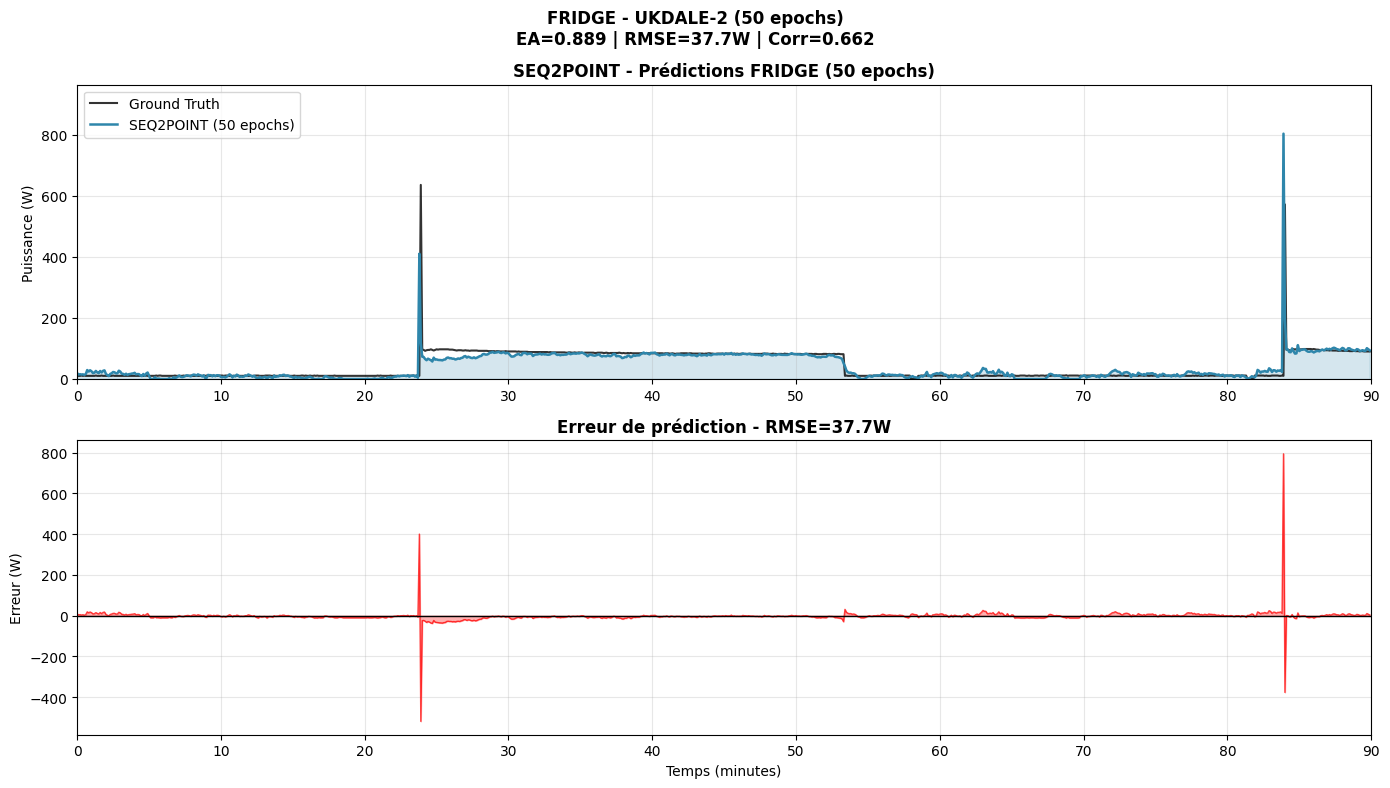

💾 fridge_seq2point_50epochs_ukdale-2.png

📊 SEQ2SEQ:


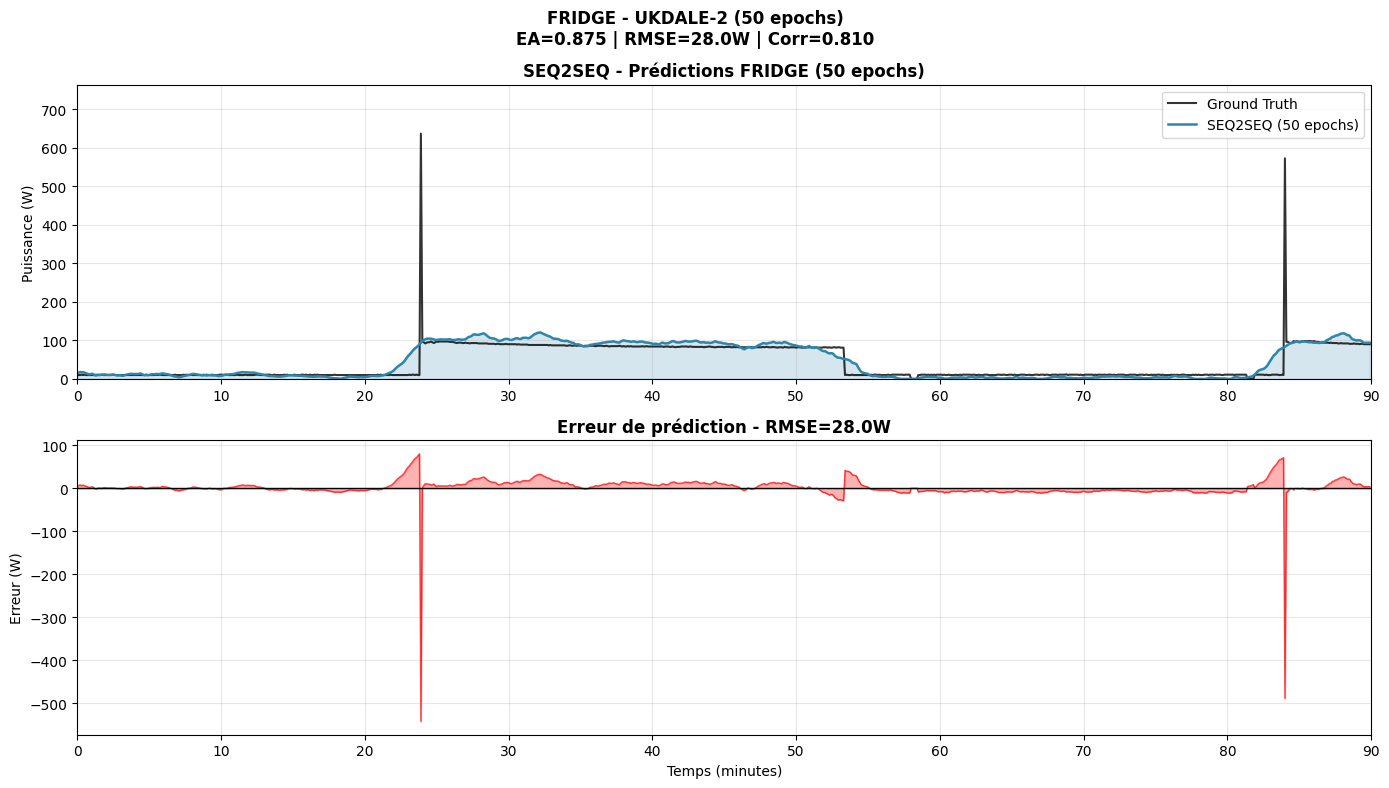

💾 fridge_seq2seq_50epochs_ukdale-2.png


In [11]:
# ============================================================================
# CELL 10: Visualisation des prédictions (INDÉPENDANT)
# ============================================================================

def plot_fridge_predictions(test_data, model_info, model_type='seq2point', window_minutes=90):
    """Visualise les prédictions du fridge"""
    
    df = test_data['df']
    fridge_meter = test_data['fridge_meter']
    
    if fridge_meter not in df.columns:
        print(f"❌ {fridge_meter} non trouvé!")
        return
    
    power = df[fridge_meter].values
    n_pts = window_minutes * 10
    
    # Prendre une fenêtre avec activité
    start_i = max(0, len(power) // 2 - n_pts // 2)
    end_i = start_i + n_pts
    
    if end_i > len(power):
        start_i = max(0, len(power) - n_pts)
        end_i = start_i + n_pts
    
    true_seg = power[start_i:end_i]
    time_min = np.arange(len(true_seg)) * 6 / 60
    
    mains_s = pd.Series(df[test_data['monitored_meters']].sum(axis=1).values[start_i:end_i])
    
    pred = predict_fridge(mains_s, model_info, model_type)
    pred = np.clip(pred, 0, None)
    
    min_len = min(len(true_seg), len(pred))
    true_seg = true_seg[:min_len]
    pred = pred[:min_len]
    
    metrics = NILMMetrics.compute_all(true_seg, pred)
    
    y_max = max(true_seg.max(), pred.max()) * 1.2
    if y_max < 10:
        y_max = 100
    
    fig, axes = plt.subplots(2, 1, figsize=(14, 8))
    
    ax1 = axes[0]
    ax1.plot(time_min[:min_len], true_seg, color='black', lw=1.5, alpha=0.8, label='Ground Truth')
    ax1.plot(time_min[:min_len], pred, color='#2E86AB', lw=1.8, label=f'{model_type.upper()} (50 epochs)')
    ax1.fill_between(time_min[:min_len], 0, pred, alpha=0.2, color='#2E86AB')
    ax1.set_ylabel('Puissance (W)')
    ax1.set_title(f'{model_type.upper()} - Prédictions FRIDGE (50 epochs)', fontweight='bold')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_xlim([0, window_minutes])
    ax1.set_ylim([0, y_max])
    
    ax2 = axes[1]
    error = pred - true_seg
    ax2.plot(time_min[:min_len], error, color='red', lw=1, alpha=0.7)
    ax2.fill_between(time_min[:min_len], 0, error, alpha=0.3, color='red')
    ax2.axhline(0, color='black', ls='-', lw=1)
    ax2.set_xlabel('Temps (minutes)')
    ax2.set_ylabel('Erreur (W)')
    ax2.set_title(f'Erreur de prédiction - RMSE={metrics["rmse"]:.1f}W', fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.set_xlim([0, window_minutes])
    
    plt.suptitle(f'FRIDGE - {test_data["name"]} (50 epochs)\n'
                 f'EA={metrics["ea"]:.3f} | RMSE={metrics["rmse"]:.1f}W | Corr={metrics["corr"]:.3f}',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    
    fname = f'fridge_{model_type}_50epochs_{test_data["name"].lower()}.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"💾 {fname}")
    
    return metrics


if fridge_models and DATA_TEST:
    print("\n" + "="*60)
    print("VISUALISATIONS FRIDGE (50 epochs)")
    print("="*60)
    
    for model_type, model_info in fridge_models.items():
        if model_info is None:
            continue
        print(f"\n📊 {model_type.upper()}:")
        plot_fridge_predictions(DATA_TEST, model_info, model_type, window_minutes=90)
else:
    print("❌ Modèles ou données non disponibles")

In [12]:
# ============================================================================
# CELL 11: Test cross-house sur toutes les maisons (INDÉPENDANT)
# ============================================================================

def test_fridge_on_all_houses(fridge_models):
    """Teste le modèle fridge sur toutes les maisons UK-DALE disponibles"""
    
    houses_to_test = ['house_1', 'house_2', 'house_5']
    all_results = {}
    
    print("\n" + "="*80)
    print("🧪 TEST FRIDGE SUR TOUTES LES MAISONS (50 epochs)")
    print("="*80)
    
    for house_key in houses_to_test:
        print(f"\n{'─'*80}")
        print(f"🏠 TEST SUR {house_key.upper()}")
        print(f"{'─'*80}")
        
        try:
            test_data = loader.load_house_data(house_key, mode='test')
            
            if test_data is None:
                print(f"  ⚠️ Pas de données pour {house_key}")
                continue
            
            df = test_data['df']
            fridge_meter = test_data['fridge_meter']
            
            if fridge_meter not in df.columns:
                print(f"  ⚠️ {fridge_meter} non trouvé dans {house_key}")
                continue
            
            true_vals = df[fridge_meter].values
            mains_vals = df[test_data['monitored_meters']].sum(axis=1).values
            
            n = min(len(true_vals), Config.MAX_TEST_SAMPLES)
            true_a = true_vals[:n]
            mains_s = pd.Series(mains_vals[:n])
            
            print(f"\n  📊 Données {house_key}:")
            print(f"     Échantillons: {n:,}")
            print(f"     FRIDGE max: {true_a.max():.0f} W")
            print(f"     FRIDGE moyenne: {true_a.mean():.1f} W")
            
            house_results = {}
            
            for model_type, model_info in fridge_models.items():
                if model_info is None:
                    continue
                    
                print(f"\n  🔬 Test {model_type.upper()}...")
                
                try:
                    pred = predict_fridge(mains_s, model_info, model_type)
                    pred = np.clip(pred, 0, None)
                    
                    min_len = min(len(true_a), len(pred))
                    metrics = NILMMetrics.compute_all(true_a[:min_len], pred[:min_len])
                    
                    house_results[model_type] = {
                        'ea': float(metrics['ea']),
                        'rmse': float(metrics['rmse']),
                        'mae': float(metrics['mae']),
                        'corr': float(metrics['corr'])
                    }
                    
                    print(f"     EA={metrics['ea']:.4f} | RMSE={metrics['rmse']:.1f}W | MAE={metrics['mae']:.1f}W")
                    
                except Exception as e:
                    print(f"     ❌ Erreur: {e}")
                    continue
            
            if house_results:
                all_results[house_key] = house_results
                
                print(f"\n  ✅ RÉSUMÉ {house_key}:")
                for model_type, m in house_results.items():
                    print(f"     {model_type.upper()}: EA={m['ea']:.4f}, RMSE={m['rmse']:.1f}W")
                    
        except Exception as e:
            print(f"  ❌ Erreur chargement {house_key}: {e}")
            continue
    
    return all_results


if fridge_models and loader:
    all_house_results = test_fridge_on_all_houses(fridge_models)
    
    # Afficher tableau récapitulatif
    print("\n" + "="*80)
    print("📊 TABLEAU RÉCAPITULATIF - FRIDGE (sans seuil)")
    print("="*80)
    print(f"Window size: {Config.WINDOW_SIZE} pts = {Config.WINDOW_SIZE*6/60:.0f} min")
    print(f"Epochs: {Config.EPOCHS}")
    print("="*80)
    
    print(f"\n{'Maison':<12} {'Modèle':<12} {'EA':>8} {'RMSE(W)':>10} {'MAE(W)':>10} {'Corr':>8}")
    print("-"*70)
    
    for house in sorted(all_house_results.keys()):
        for model_type in ['seq2point', 'seq2seq']:
            if model_type in all_house_results[house]:
                m = all_house_results[house][model_type]
                print(f"{house:<12} {model_type:<12} "
                      f"{m['ea']:>8.4f} {m['rmse']:>10.1f} "
                      f"{m['mae']:>10.1f} {m['corr']:>8.4f}")
    
    print("\n" + "="*80)
else:
    print("❌ Modèles ou loader non disponibles")
    all_house_results = None


🧪 TEST FRIDGE SUR TOUTES LES MAISONS (50 epochs)

────────────────────────────────────────────────────────────────────────────────
🏠 TEST SUR HOUSE_1
────────────────────────────────────────────────────────────────────────────────

TEST: UKDALE-1
Période: 2014-04-01 → 2014-05-01
FRIDGE compteur: meter12
✅ meter12: 19,381,298 points
✅ 29 compteurs chargés
⚠️ Pas de données dans la période sélectionnée!
  ⚠️ Pas de données pour house_1

────────────────────────────────────────────────────────────────────────────────
🏠 TEST SUR HOUSE_2
────────────────────────────────────────────────────────────────────────────────

TEST: UKDALE-2
Période: 2013-07-28 → 2013-08-11
FRIDGE compteur: meter14
✅ meter14: 1,687,285 points
✅ 20 compteurs chargés
Grille: 201,601 points

📊 FRIDGE (meter14) - test:
   Max: 1295 W
   Moy: 33.9 W
   Points: 201,601

  📊 Données house_2:
     Échantillons: 100,000
     FRIDGE max: 1283 W
     FRIDGE moyenne: 57.6 W

  🔬 Test SEQ2POINT...
     EA=0.7995 | RMSE=35.2W | 

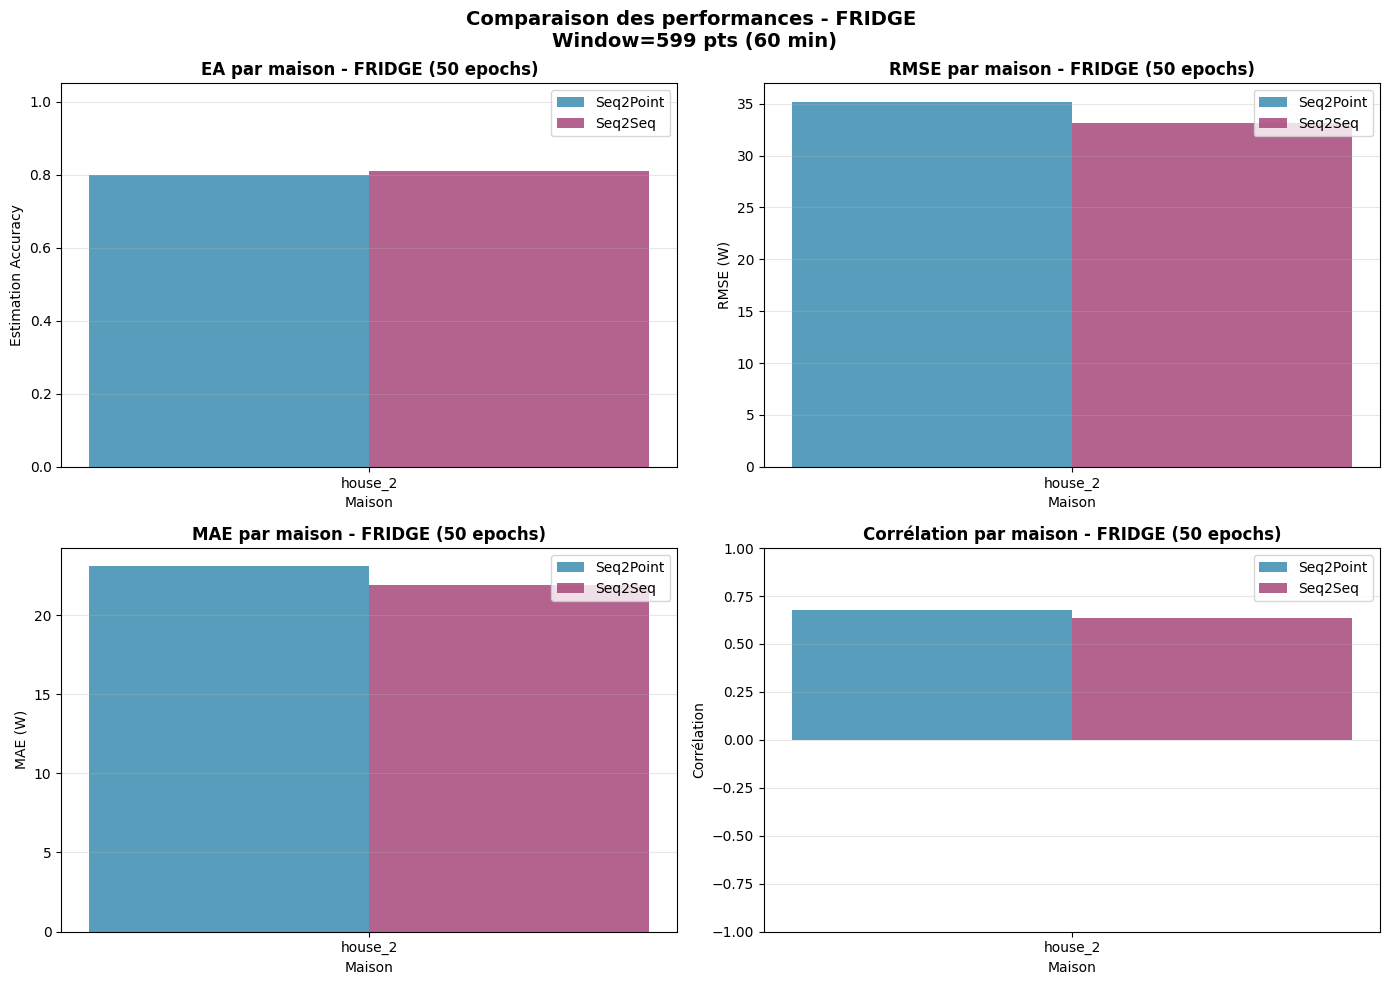

💾 fridge_comparison_all_houses_50epochs.png


In [13]:
# ============================================================================
# CELL 12: Graphique comparatif des performances (INDÉPENDANT)
# ============================================================================

def plot_comparison_all_houses(all_results):
    """Graphique comparatif des performances par maison pour fridge"""
    
    if not all_results:
        print("❌ Aucun résultat à visualiser")
        return
    
    houses = list(all_results.keys())
    n_houses = len(houses)
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    x = np.arange(n_houses)
    width = 0.35
    
    ea_point = []
    ea_seq = []
    rmse_point = []
    rmse_seq = []
    mae_point = []
    mae_seq = []
    corr_point = []
    corr_seq = []
    
    for house in houses:
        ea_point.append(all_results[house].get('seq2point', {}).get('ea', 0))
        ea_seq.append(all_results[house].get('seq2seq', {}).get('ea', 0))
        rmse_point.append(all_results[house].get('seq2point', {}).get('rmse', 0))
        rmse_seq.append(all_results[house].get('seq2seq', {}).get('rmse', 0))
        mae_point.append(all_results[house].get('seq2point', {}).get('mae', 0))
        mae_seq.append(all_results[house].get('seq2seq', {}).get('mae', 0))
        corr_point.append(all_results[house].get('seq2point', {}).get('corr', 0))
        corr_seq.append(all_results[house].get('seq2seq', {}).get('corr', 0))
    
    # 1. EA par maison
    ax1 = axes[0, 0]
    ax1.bar(x - width/2, ea_point, width, label='Seq2Point', color='#2E86AB', alpha=0.8)
    ax1.bar(x + width/2, ea_seq, width, label='Seq2Seq', color='#A23B72', alpha=0.8)
    ax1.set_xlabel('Maison')
    ax1.set_ylabel('Estimation Accuracy')
    ax1.set_title('EA par maison - FRIDGE (50 epochs)', fontweight='bold')
    ax1.set_xticks(x)
    ax1.set_xticklabels(houses)
    ax1.legend()
    ax1.grid(True, alpha=0.3, axis='y')
    ax1.set_ylim([0, 1.05])
    
    # 2. RMSE par maison
    ax2 = axes[0, 1]
    ax2.bar(x - width/2, rmse_point, width, label='Seq2Point', color='#2E86AB', alpha=0.8)
    ax2.bar(x + width/2, rmse_seq, width, label='Seq2Seq', color='#A23B72', alpha=0.8)
    ax2.set_xlabel('Maison')
    ax2.set_ylabel('RMSE (W)')
    ax2.set_title('RMSE par maison - FRIDGE (50 epochs)', fontweight='bold')
    ax2.set_xticks(x)
    ax2.set_xticklabels(houses)
    ax2.legend()
    ax2.grid(True, alpha=0.3, axis='y')
    
    # 3. MAE par maison
    ax3 = axes[1, 0]
    ax3.bar(x - width/2, mae_point, width, label='Seq2Point', color='#2E86AB', alpha=0.8)
    ax3.bar(x + width/2, mae_seq, width, label='Seq2Seq', color='#A23B72', alpha=0.8)
    ax3.set_xlabel('Maison')
    ax3.set_ylabel('MAE (W)')
    ax3.set_title('MAE par maison - FRIDGE (50 epochs)', fontweight='bold')
    ax3.set_xticks(x)
    ax3.set_xticklabels(houses)
    ax3.legend()
    ax3.grid(True, alpha=0.3, axis='y')
    
    # 4. Corrélation par maison
    ax4 = axes[1, 1]
    ax4.bar(x - width/2, corr_point, width, label='Seq2Point', color='#2E86AB', alpha=0.8)
    ax4.bar(x + width/2, corr_seq, width, label='Seq2Seq', color='#A23B72', alpha=0.8)
    ax4.set_xlabel('Maison')
    ax4.set_ylabel('Corrélation')
    ax4.set_title('Corrélation par maison - FRIDGE (50 epochs)', fontweight='bold')
    ax4.set_xticks(x)
    ax4.set_xticklabels(houses)
    ax4.legend()
    ax4.grid(True, alpha=0.3, axis='y')
    ax4.set_ylim([-1, 1])
    
    plt.suptitle(f'Comparaison des performances - FRIDGE \n'
                 f'Window={Config.WINDOW_SIZE} pts ({Config.WINDOW_SIZE*6/60:.0f} min)',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('fridge_comparison_all_houses_50epochs.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("💾 fridge_comparison_all_houses_50epochs.png")


if all_house_results:
    plot_comparison_all_houses(all_house_results)

In [14]:
# ============================================================================
# CELL 13: Sauvegarde des résultats (INDÉPENDANT)
# ============================================================================

def save_all_results(fridge_models, all_results, results_dir='/kaggle/working/fridge_results_50epochs'):
    """Sauvegarde tous les résultats du fridge"""
    
    os.makedirs(results_dir, exist_ok=True)
    
    print("\n📦 Sauvegarde des modèles:")
    model_files = glob.glob('/kaggle/working/fridge_*.keras')
    for f in model_files:
        dest = os.path.join(results_dir, os.path.basename(f))
        shutil.copy(f, dest)
        print(f"  ✅ {os.path.basename(f)}")
    
    # Sauvegarde des métriques
    if fridge_models:
        results = {}
        for model_type, model_info in fridge_models.items():
            if model_info and 'test_metrics' in model_info:
                results[model_type] = {
                    'ea': float(model_info['test_metrics']['ea']),
                    'rmse': float(model_info['test_metrics']['rmse']),
                    'mae': float(model_info['test_metrics']['mae']),
                    'corr': float(model_info['test_metrics']['corr']),
                    'best_epoch': int(model_info['best_epoch'])
                }
        
        with open(os.path.join(results_dir, 'metrics.json'), 'w') as f:
            json.dump(results, f, indent=2)
        print("  ✅ metrics.json")
    
    # Sauvegarde des résultats cross-house
    if all_results:
        with open(os.path.join(results_dir, 'cross_house_results.json'), 'w') as f:
            json.dump(all_results, f, indent=2)
        print("  ✅ cross_house_results.json")
    
    # Rapport
    with open(os.path.join(results_dir, 'README.txt'), 'w') as f:
        f.write("="*60 + "\n")
        f.write("RÉSULTATS FRIDGE NILM (50 EPOCHS - SANS SEUIL)\n")
        f.write("="*60 + "\n\n")
        f.write(f"Window size: {Config.WINDOW_SIZE} pts = {Config.WINDOW_SIZE*6/60:.0f} min\n")
        f.write(f"Epochs: {Config.EPOCHS}\n")
        f.write(f"Train house: house_1 (meter12)\n\n")
        
        f.write("Performances sur house_2 (test):\n")
        if fridge_models:
            for model_type, model_info in fridge_models.items():
                if model_info and 'test_metrics' in model_info:
                    m = model_info['test_metrics']
                    f.write(f"  {model_type.upper()}: EA={m['ea']:.4f}, RMSE={m['rmse']:.1f}W, MAE={m['mae']:.1f}W\n")
        
        f.write("\nPerformances cross-house:\n")
        if all_results:
            for house, res in all_results.items():
                for model_type, m in res.items():
                    f.write(f"  {house} [{model_type}]: EA={m['ea']:.4f}, RMSE={m['rmse']:.1f}W\n")
    
    print("  ✅ README.txt")
    print(f"\n📁 Résultats sauvegardés dans: {results_dir}")


if fridge_models:
    save_all_results(fridge_models, all_house_results)
    print("\n✅ Sauvegarde terminée!")
else:
    print("❌ Rien à sauvegarder")


📦 Sauvegarde des modèles:
  ✅ fridge_seq2seq.keras
  ✅ fridge_seq2point.keras
  ✅ metrics.json
  ✅ cross_house_results.json
  ✅ README.txt

📁 Résultats sauvegardés dans: /kaggle/working/fridge_results_50epochs

✅ Sauvegarde terminée!


In [15]:
# ============================================================================
# CELL 14: Rapport final avec accès utilisateur (INDÉPENDANT)
# ============================================================================

print("\n" + "="*80)
print("📋 RAPPORT FINAL - FRIDGE NILM (50 EPOCHS - SANS SEUIL)")
print("="*80)

print(f"""
╔══════════════════════════════════════════════════════════════════════════════╗
║                           CONFIGURATION DU MODÈLE                            ║
╠══════════════════════════════════════════════════════════════════════════════╣
║  Appareil:              FRIDGE (Réfrigérateur)                               ║
║  Compteur (train):      meter12 (Building 1 - fridge freezer)               ║
║  Compteur (test):       meter14 (Building 2 - fridge)                       ║
║  Compteur (test):       meter19 (Building 5 - fridge freezer)               ║
║  Seuil:                 PAS DE SEUIL (fonctionnement continu)               ║
║  Window size:           {Config.WINDOW_SIZE} pts ({Config.WINDOW_SIZE*6/60:.0f} min)    ║
║  Epochs:                {Config.EPOCHS}                                                     ║
╚══════════════════════════════════════════════════════════════════════════════╝
""")

print("📈 MODÈLES ENTRAÎNÉS:")
if fridge_models:
    for model_type, model_info in fridge_models.items():
        if model_info:
            print(f"  ✅ {model_type.upper()} — meilleure epoch: {model_info['best_epoch']}")
else:
    print("  ❌ Aucun modèle entraîné")

print("\n📊 PERFORMANCES SUR HOUSE_2 (test):")
if fridge_models:
    for model_type, model_info in fridge_models.items():
        if model_info and 'test_metrics' in model_info:
            m = model_info['test_metrics']
            print(f"  {model_type.upper()}: EA={m['ea']:.4f} | RMSE={m['rmse']:.1f}W | MAE={m['mae']:.1f}W | Corr={m['corr']:.4f}")
else:
    print("  ❌ Aucune performance disponible")

print("\n📁 FICHIERS GÉNÉRÉS:")
for f in sorted(glob.glob('/kaggle/working/fridge_*.keras') + 
                glob.glob('/kaggle/working/fridge_*.png') + 
                glob.glob('/kaggle/working/fridge_*.json') +
                glob.glob('/kaggle/working/fridge_results_50epochs/*')):
    if os.path.exists(f):
        size = os.path.getsize(f) / 1e6
        print(f"  📄 {os.path.basename(f):<50} {size:.1f} MB")

print("\n" + "="*80)
print("🎯 ACCÈS UTILISATEUR - POUR VOIR LES RÉSULTATS:")
print("="*80)
print("""
  1. Visualisations: regardez les fichiers .png générés
  2. Métriques détaillées: ouvrez fridge_results_50epochs/metrics.json
  3. Résultats cross-house: ouvrez fridge_results_50epochs/cross_house_results.json
  4. Modèles: les fichiers .keras peuvent être chargés avec tensorflow.keras.models.load_model()
""")
print("="*80)
print("✅ PIPELINE FRIDGE TERMINÉ (50 EPOCHS - SANS SEUIL)")
print("="*80)


📋 RAPPORT FINAL - FRIDGE NILM (50 EPOCHS - SANS SEUIL)

╔══════════════════════════════════════════════════════════════════════════════╗
║                           CONFIGURATION DU MODÈLE                            ║
╠══════════════════════════════════════════════════════════════════════════════╣
║  Appareil:              FRIDGE (Réfrigérateur)                               ║
║  Compteur (train):      meter12 (Building 1 - fridge freezer)               ║
║  Compteur (test):       meter14 (Building 2 - fridge)                       ║
║  Compteur (test):       meter19 (Building 5 - fridge freezer)               ║
║  Seuil:                 PAS DE SEUIL (fonctionnement continu)               ║
║  Window size:           599 pts (60 min)    ║
║  Epochs:                50                                                     ║
╚══════════════════════════════════════════════════════════════════════════════╝

📈 MODÈLES ENTRAÎNÉS:
  ✅ SEQ2POINT — meilleure epoch: 45
  ✅ SEQ2SEQ — meilleure epoch

In [16]:
# ============================================================================
# CELL: Visualisation interactive du FRIDGE sur house_2 (période personnalisable)
# ============================================================================

def visualize_fridge_custom_period(test_data, model_info, model_type='seq2point', 
                                   start_date=None, end_date=None, duration_hours=6):
    """
    Visualise les prédictions du fridge sur une période personnalisée
    
    Paramètres:
    - test_data: données de test (house_2)
    - model_info: modèle entraîné
    - model_type: 'seq2point' ou 'seq2seq'
    - start_date: date de début (ex: '2013-07-30 00:00:00')
    - end_date: date de fin (ex: '2013-07-30 12:00:00')
    - duration_hours: durée en heures (si start_date seul)
    """
    
    df = test_data['df']
    fridge_meter = test_data['fridge_meter']
    threshold = Config.get_threshold()
    
    if fridge_meter not in df.columns:
        print(f"❌ {fridge_meter} non trouvé!")
        return None
    
    # Convertir l'index en datetime
    df.index = pd.to_datetime(df.index)
    
    # Déterminer la période
    if start_date is None:
        # Par défaut: prendre une période au milieu des données
        mid_point = len(df) // 2
        start_date = df.index[mid_point]
        end_date = start_date + pd.Timedelta(hours=duration_hours)
    elif end_date is None:
        end_date = pd.to_datetime(start_date) + pd.Timedelta(hours=duration_hours)
    else:
        start_date = pd.to_datetime(start_date)
        end_date = pd.to_datetime(end_date)
    
    print(f"\n{'='*80}")
    print(f"📊 VISUALISATION FRIDGE - Période sélectionnée")
    print(f"{'='*80}")
    print(f"   Date début: {start_date}")
    print(f"   Date fin:   {end_date}")
    print(f"   Durée:      {duration_hours} heures")
    print(f"   Modèle:     {model_type.upper()}")
    print(f"{'='*80}")
    
    # Filtrer les données sur la période
    mask = (df.index >= start_date) & (df.index <= end_date)
    df_period = df.loc[mask]
    
    if len(df_period) == 0:
        print(f"❌ Aucune donnée trouvée sur cette période!")
        print(f"   Période disponible: {df.index.min()} → {df.index.max()}")
        return None
    
    # Extraire les données
    true_vals = df_period[fridge_meter].values
    mains_vals = df_period[test_data['monitored_meters']].sum(axis=1).values
    
    # Prédiction
    mains_s = pd.Series(mains_vals)
    pred = predict_fridge(mains_s, model_info, model_type)
    pred = np.clip(pred, 0, None)
    
    # Ajuster les longueurs
    min_len = min(len(true_vals), len(pred))
    true_vals = true_vals[:min_len]
    pred = pred[:min_len]
    
    # Calculer les métriques
    metrics = NILMMetrics.compute_all(true_vals, pred)
    
    # Créer l'axe des temps (en minutes)
    time_min = np.arange(len(true_vals)) * 6 / 60
    
    # Graphique
    fig, axes = plt.subplots(2, 1, figsize=(16, 10))
    
    # Graphique 1: Ground Truth vs Prédiction
    ax1 = axes[0]
    ax1.plot(time_min, true_vals, color='black', lw=1.5, alpha=0.8, label='Ground Truth (réel)')
    ax1.plot(time_min, pred, color='#2E86AB', lw=1.8, label=f'{model_type.upper()} (prédit)')
    ax1.fill_between(time_min, 0, pred, alpha=0.2, color='#2E86AB')
    ax1.set_ylabel('Puissance (W)', fontsize=12)
    ax1.set_title(f'FRIDGE - {model_type.upper()} | EA={metrics["ea"]:.3f} | RMSE={metrics["rmse"]:.1f}W | Corr={metrics["corr"]:.3f}', 
                  fontsize=14, fontweight='bold')
    ax1.legend(loc='upper right')
    ax1.grid(True, alpha=0.3)
    ax1.set_xlim([0, time_min[-1]])
    
    # Graphique 2: Erreur
    ax2 = axes[1]
    error = pred - true_vals
    ax2.plot(time_min, error, color='red', lw=1, alpha=0.7, label='Erreur (prédit - réel)')
    ax2.fill_between(time_min, 0, error, alpha=0.3, color='red')
    ax2.axhline(0, color='black', ls='-', lw=1)
    ax2.axhline(metrics['rmse'], color='orange', ls='--', lw=1, label=f'RMSE: {metrics["rmse"]:.1f}W')
    ax2.axhline(-metrics['rmse'], color='orange', ls='--', lw=1)
    ax2.set_xlabel('Temps (minutes)', fontsize=12)
    ax2.set_ylabel('Erreur (W)', fontsize=12)
    ax2.set_title(f'Erreur de prédiction - MAE={metrics["mae"]:.1f}W | RMSE={metrics["rmse"]:.1f}W', 
                  fontsize=14, fontweight='bold')
    ax2.legend(loc='upper right')
    ax2.grid(True, alpha=0.3)
    ax2.set_xlim([0, time_min[-1]])
    
    # Ajouter les dates sur l'axe des x
    dates = df_period.index[:min_len]
    step = max(1, len(dates) // 8)
    xticks_pos = np.arange(0, len(dates), step) * 6 / 60
    xticks_labels = [dates[i].strftime('%H:%M') for i in range(0, len(dates), step)]
    ax1.set_xticks(xticks_pos)
    ax1.set_xticklabels(xticks_labels, rotation=45)
    ax2.set_xticks(xticks_pos)
    ax2.set_xticklabels(xticks_labels, rotation=45)
    
    plt.suptitle(f'FRIDGE - {test_data["name"]}\n{start_date.strftime("%Y-%m-%d %H:%M")} → {end_date.strftime("%Y-%m-%d %H:%M")}',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    
    # Sauvegarde
    fname = f'fridge_{model_type}_custom_{start_date.strftime("%Y%m%d_%H%M")}.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"\n💾 Figure sauvegardée: {fname}")
    print(f"\n📊 MÉTRIQUES sur la période sélectionnée:")
    print(f"   Estimation Accuracy (EA): {metrics['ea']:.4f}")
    print(f"   RMSE: {metrics['rmse']:.1f} W")
    print(f"   MAE:  {metrics['mae']:.1f} W")
    print(f"   Corrélation: {metrics['corr']:.4f}")
    
    return metrics

In [17]:
# ============================================================================
# CELL: Afficher les périodes disponibles dans les données de test
# ============================================================================

def show_available_periods(test_data):
    """Affiche les périodes disponibles et suggère des intervalles"""
    
    if test_data is None:
        print("❌ Données de test non disponibles")
        return
    
    df = test_data['df']
    df.index = pd.to_datetime(df.index)
    
    print("\n" + "="*80)
    print("📅 PÉRIODES DISPONIBLES DANS LES DONNÉES DE TEST")
    print("="*80)
    print(f"\n   Maison: {test_data['name']}")
    print(f"   Période complète: {df.index.min()} → {df.index.max()}")
    print(f"   Durée totale: {(df.index.max() - df.index.min()).days} jours")
    print(f"   Nombre d'échantillons: {len(df):,}")
    
    # Trouver des périodes avec activité du fridge
    fridge_meter = test_data['fridge_meter']
    fridge_power = df[fridge_meter].values
    
    # Détecter les périodes où le fridge consomme > 50W
    active_mask = fridge_power > 50
    
    # Trouver les plages actives
    changes = np.diff(np.concatenate(([0], active_mask.astype(int), [0])))
    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]
    
    print(f"\n🔍 Périodes avec activité FRIDGE (>50W):")
    print(f"   {len(starts)} périodes détectées\n")
    
    print("   Exemples de périodes (premières 10):")
    print("   " + "-"*60)
    for i in range(min(10, len(starts))):
        start_idx = starts[i]
        end_idx = ends[i] if i < len(ends) else start_idx + 100
        start_time = df.index[start_idx]
        end_time = df.index[end_idx] if end_idx < len(df) else df.index[-1]
        duration = (end_time - start_time).total_seconds() / 60
        print(f"   {i+1:2d}. {start_time} → {end_time.strftime('%H:%M:%S')} (durée: {duration:.0f} min)")
    
    print("\n" + "="*80)
    print("💡 EXEMPLES DE PÉRIODES À TESTER:")
    print("="*80)
    
    # Proposer des périodes intéressantes
    examples = [
        ("Journée typique", df.index[len(df)//4], 12),
        ("Période 2", df.index[len(df)//2], 6),
        ("Période 3", df.index[3*len(df)//4], 8),
    ]
    
    for name, start, hours in examples:
        end = start + pd.Timedelta(hours=hours)
        print(f"\n   {name}:")
        print(f"     start_date='{start}'")
        print(f"     end_date='{end}'")
        print(f"     # OU duration_hours={hours}")
    
    return df.index.min(), df.index.max()


# Afficher les périodes disponibles
if DATA_TEST:
    min_date, max_date = show_available_periods(DATA_TEST)


📅 PÉRIODES DISPONIBLES DANS LES DONNÉES DE TEST

   Maison: UKDALE-2
   Période complète: 2013-07-28 00:00:00+01:00 → 2013-08-03 22:39:54+01:00
   Durée totale: 6 jours
   Nombre d'échantillons: 100,000

🔍 Périodes avec activité FRIDGE (>50W):
   128 périodes détectées

   Exemples de périodes (premières 10):
   ------------------------------------------------------------
    1. 2013-07-28 00:04:36+01:00 → 04:18:42 (durée: 254 min)
    2. 2013-07-28 04:56:24+01:00 → 06:34:42 (durée: 98 min)
    3. 2013-07-28 07:12:00+01:00 → 09:15:24 (durée: 123 min)
    4. 2013-07-28 09:46:06+01:00 → 11:16:18 (durée: 90 min)
    5. 2013-07-28 11:53:24+01:00 → 14:27:12 (durée: 154 min)
    6. 2013-07-28 15:06:36+01:00 → 16:49:30 (durée: 103 min)
    7. 2013-07-28 17:30:24+01:00 → 19:47:18 (durée: 137 min)
    8. 2013-07-28 20:18:24+01:00 → 20:45:06 (durée: 27 min)
    9. 2013-07-28 21:15:54+01:00 → 21:44:24 (durée: 28 min)
   10. 2013-07-28 22:10:00+01:00 → 22:47:36 (durée: 38 min)

💡 EXEMPLES DE PÉRI


🎬 VISUALISATIONS FRIDGE - EXEMPLES DE PÉRIODES

📊 Début des données: 2013-07-28 00:00 (+6h)

📊 VISUALISATION FRIDGE - Période sélectionnée
   Date début: 2013-07-28 00:00:00+01:00
   Date fin:   2013-07-28 06:00:00+01:00
   Durée:      6 heures
   Modèle:     SEQ2POINT


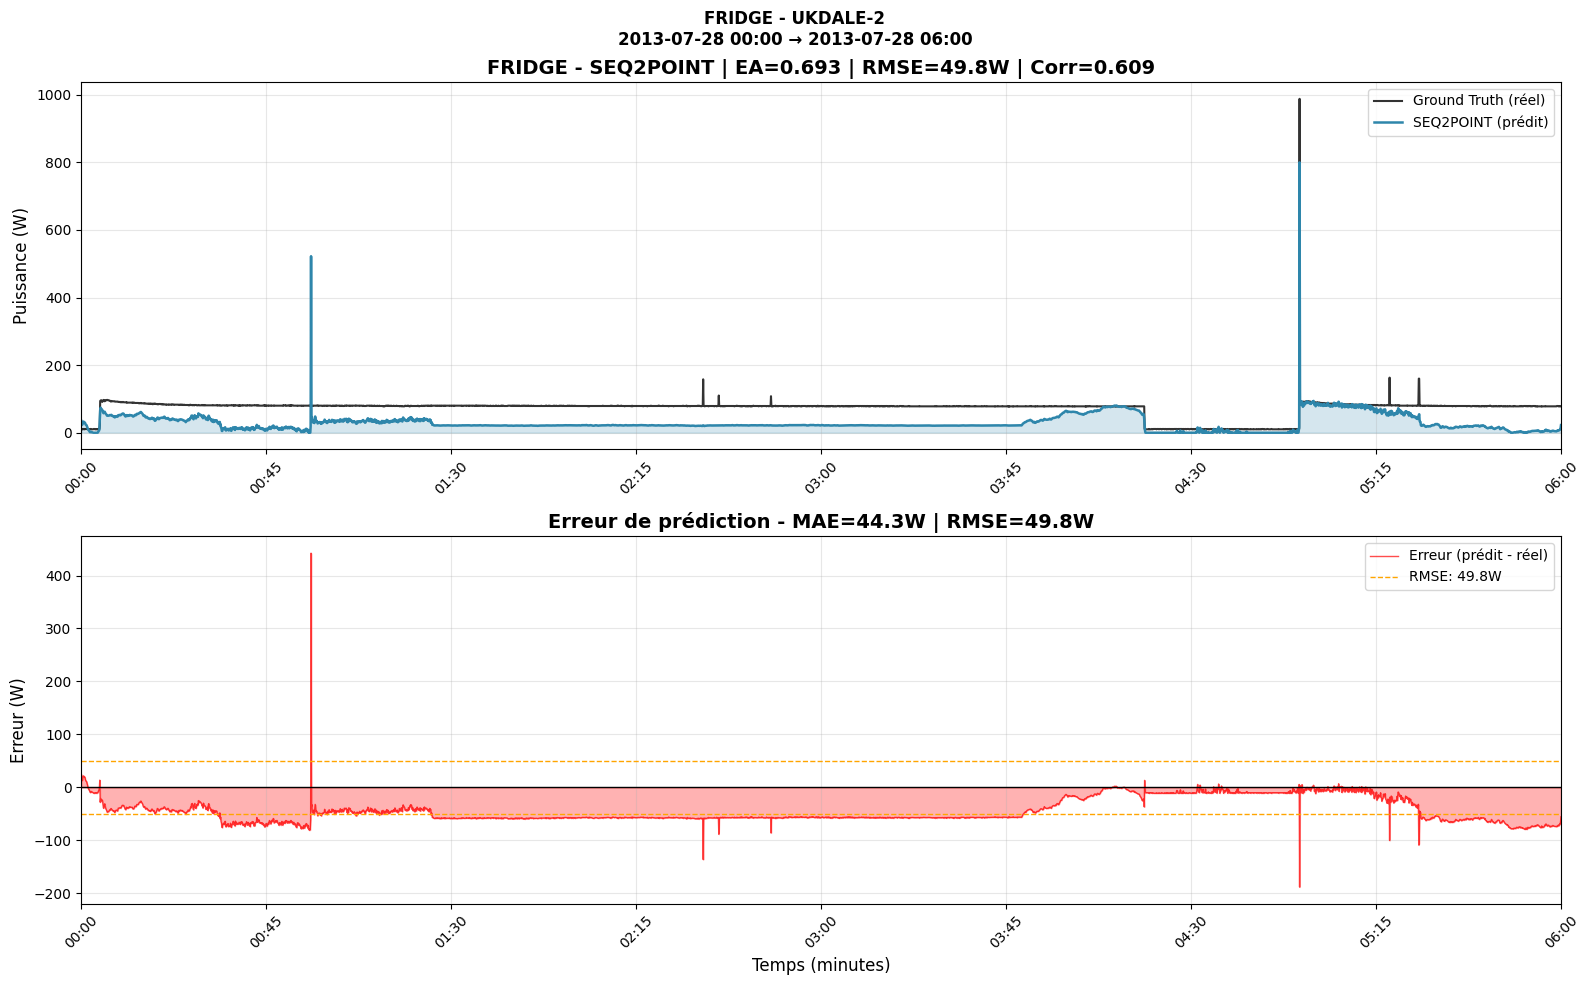


💾 Figure sauvegardée: fridge_seq2point_custom_20130728_0000.png

📊 MÉTRIQUES sur la période sélectionnée:
   Estimation Accuracy (EA): 0.6934
   RMSE: 49.8 W
   MAE:  44.3 W
   Corrélation: 0.6094

📊 VISUALISATION FRIDGE - Période sélectionnée
   Date début: 2013-07-28 00:00:00+01:00
   Date fin:   2013-07-28 06:00:00+01:00
   Durée:      6 heures
   Modèle:     SEQ2SEQ


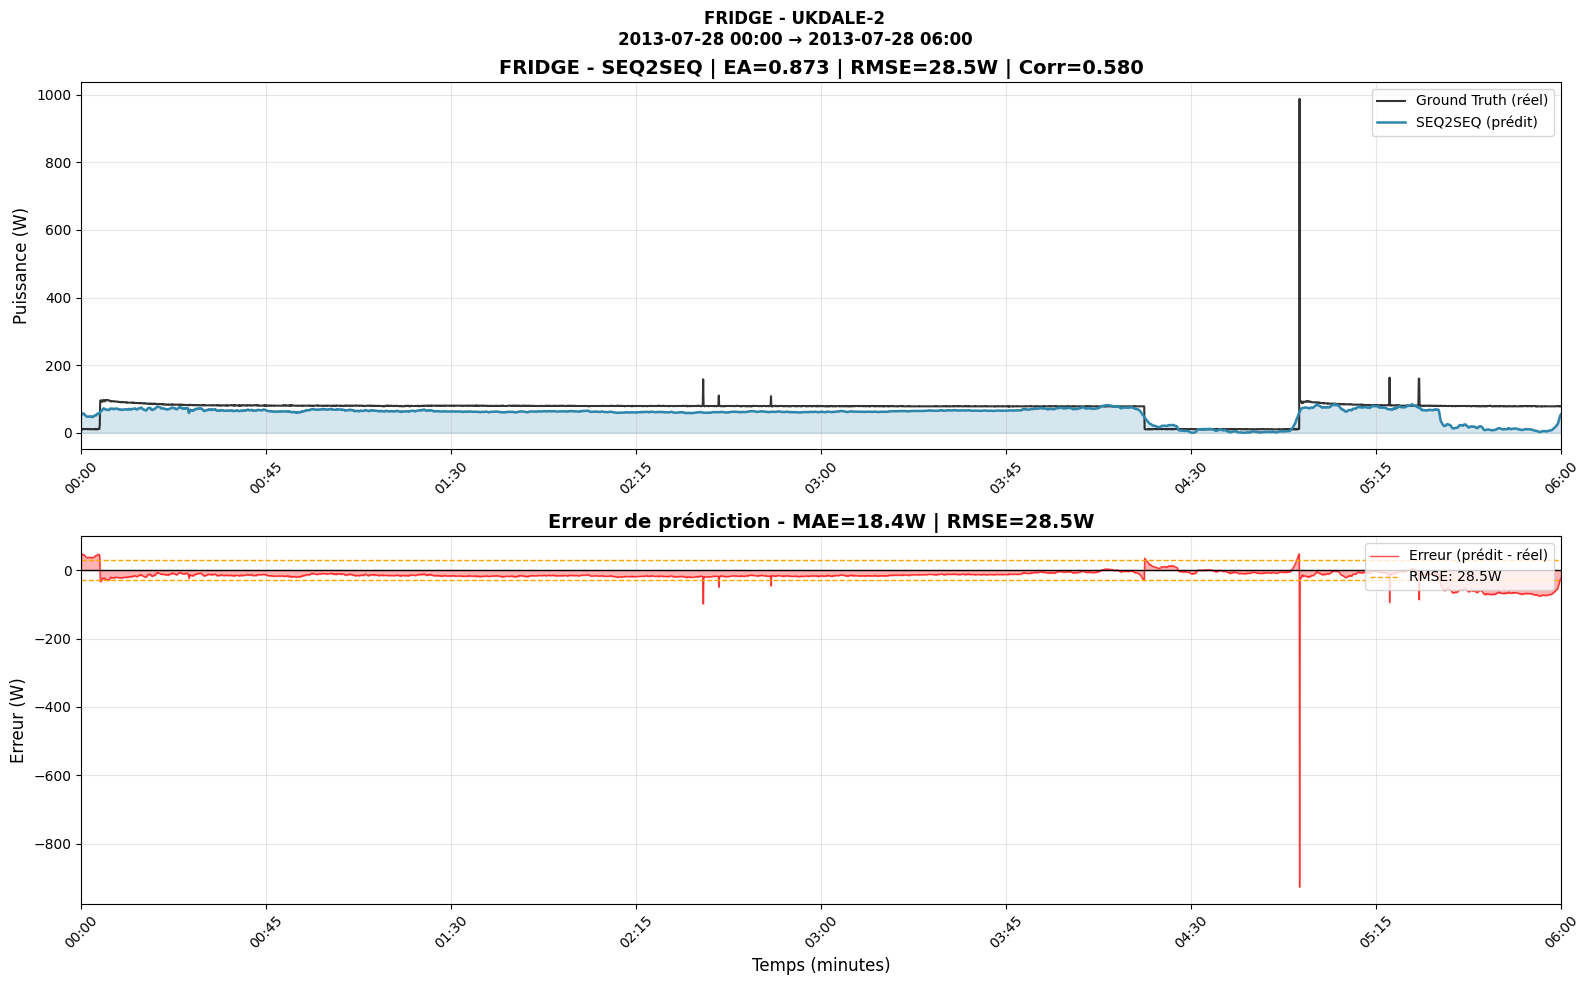


💾 Figure sauvegardée: fridge_seq2seq_custom_20130728_0000.png

📊 MÉTRIQUES sur la période sélectionnée:
   Estimation Accuracy (EA): 0.8727
   RMSE: 28.5 W
   MAE:  18.4 W
   Corrélation: 0.5799

📊 Milieu des données: 2013-07-31 11:19 (+6h)

📊 VISUALISATION FRIDGE - Période sélectionnée
   Date début: 2013-07-31 11:19:57+01:00
   Date fin:   2013-07-31 17:19:57+01:00
   Durée:      6 heures
   Modèle:     SEQ2POINT


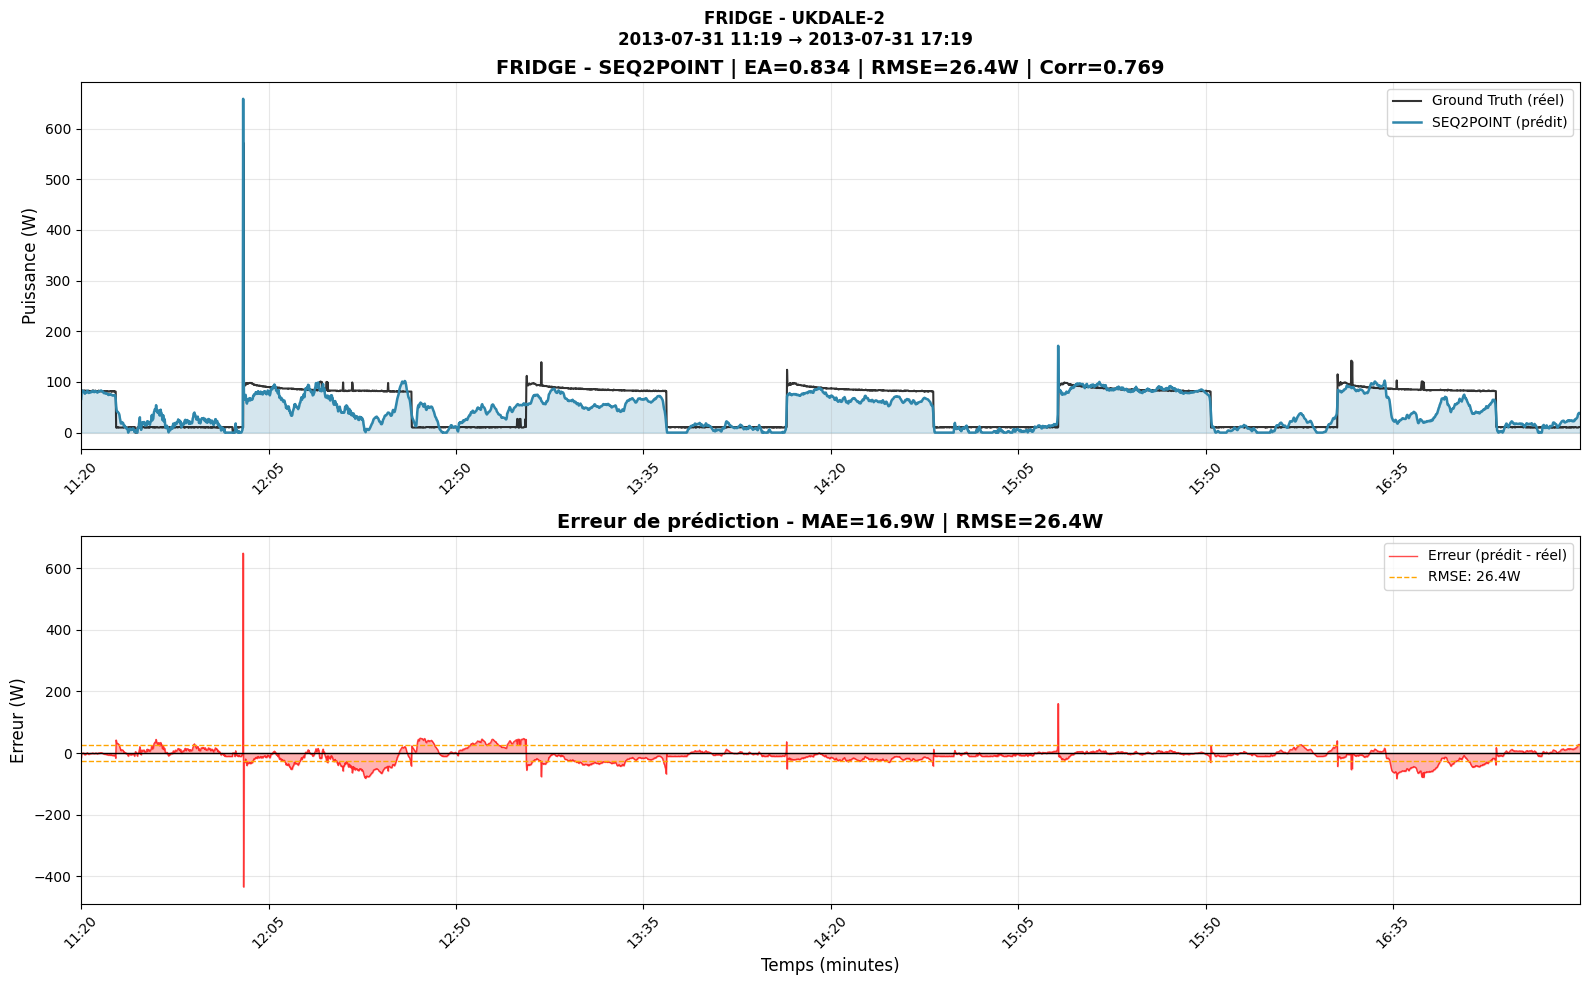


💾 Figure sauvegardée: fridge_seq2point_custom_20130731_1119.png

📊 MÉTRIQUES sur la période sélectionnée:
   Estimation Accuracy (EA): 0.8342
   RMSE: 26.4 W
   MAE:  16.9 W
   Corrélation: 0.7689

📊 VISUALISATION FRIDGE - Période sélectionnée
   Date début: 2013-07-31 11:19:57+01:00
   Date fin:   2013-07-31 17:19:57+01:00
   Durée:      6 heures
   Modèle:     SEQ2SEQ


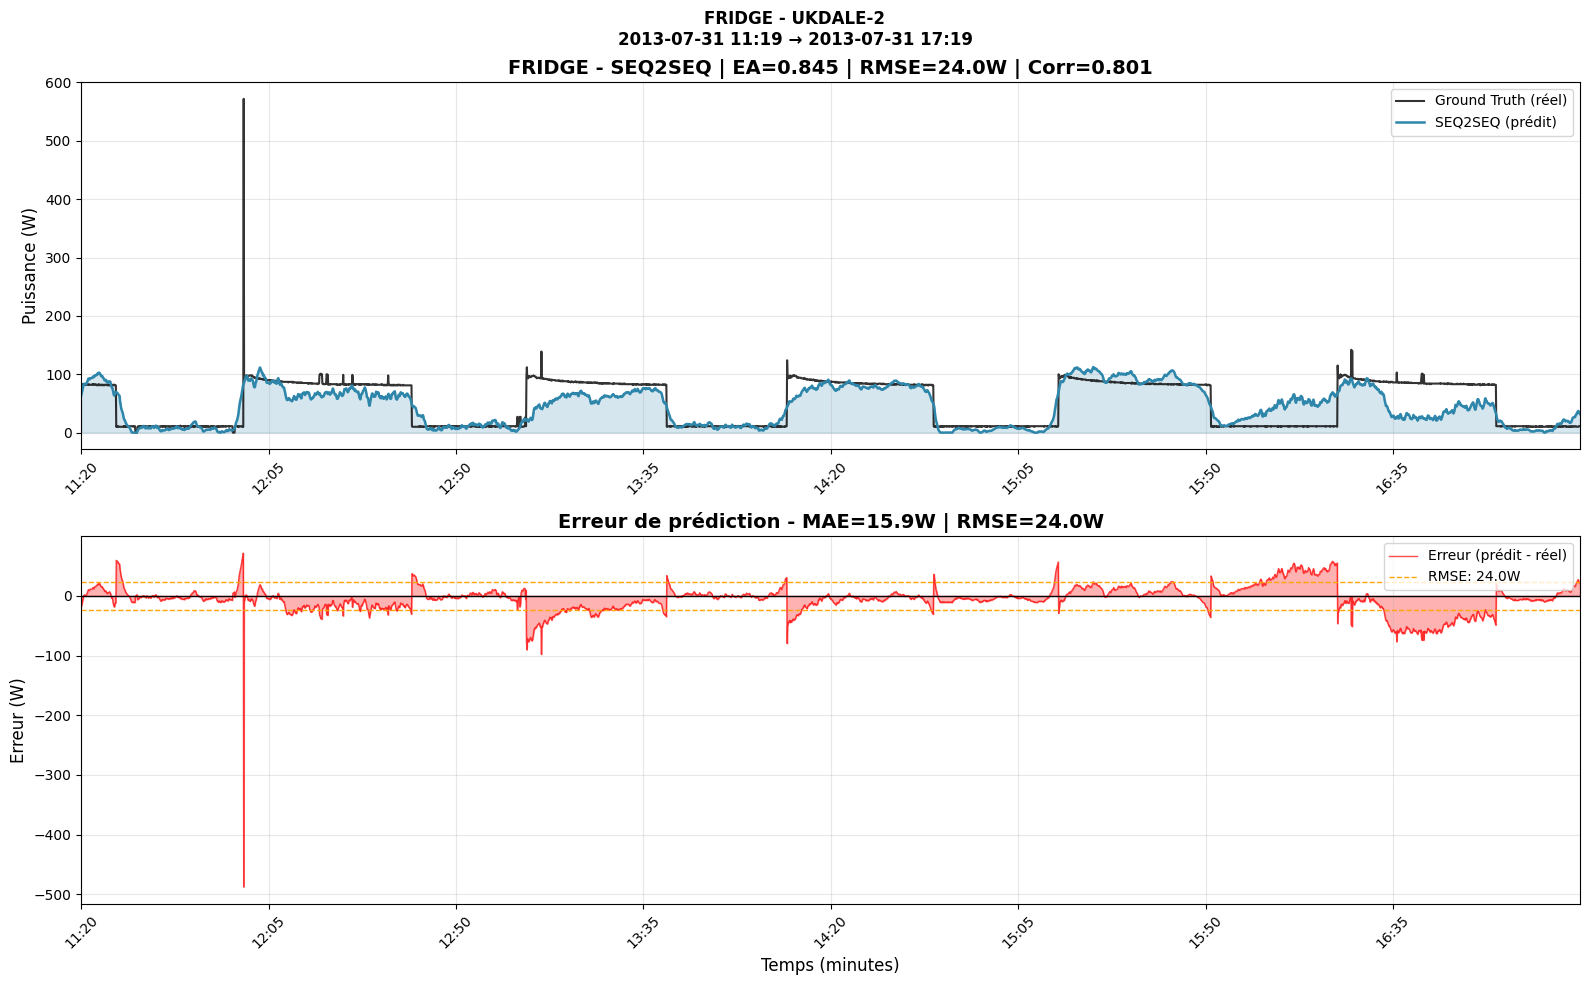


💾 Figure sauvegardée: fridge_seq2seq_custom_20130731_1119.png

📊 MÉTRIQUES sur la période sélectionnée:
   Estimation Accuracy (EA): 0.8446
   RMSE: 24.0 W
   MAE:  15.9 W
   Corrélation: 0.8014

📊 Fin des données: 2013-08-03 05:59 (+6h)

📊 VISUALISATION FRIDGE - Période sélectionnée
   Date début: 2013-08-03 05:59:54.600000+01:00
   Date fin:   2013-08-03 11:59:54.600000+01:00
   Durée:      6 heures
   Modèle:     SEQ2POINT


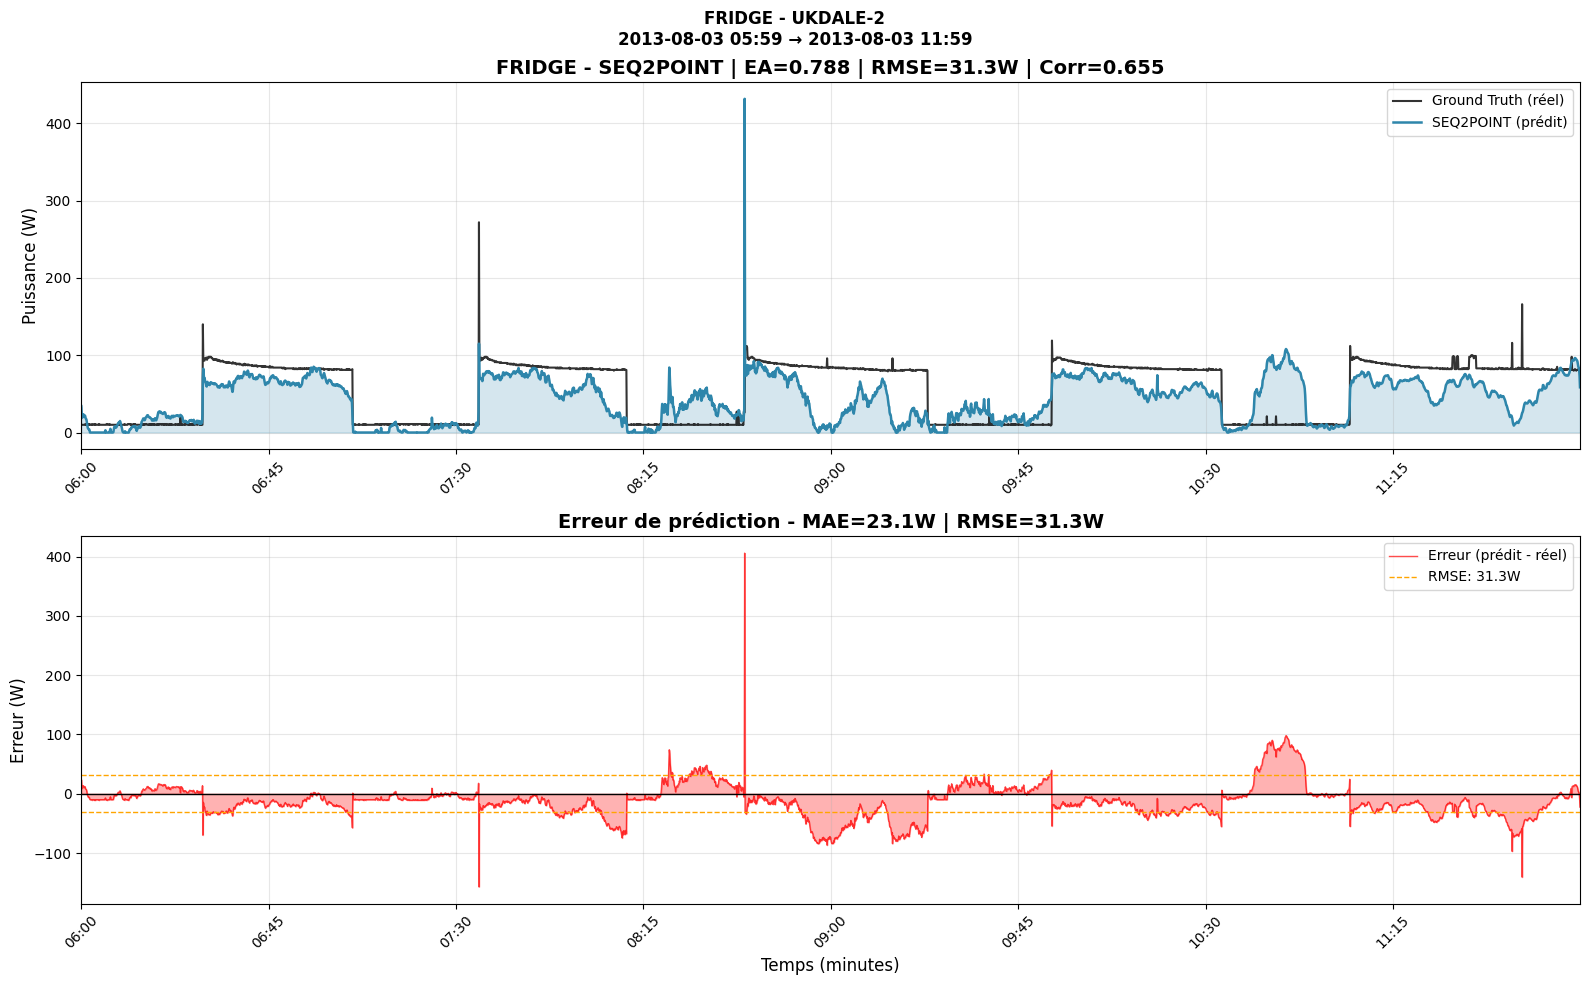


💾 Figure sauvegardée: fridge_seq2point_custom_20130803_0559.png

📊 MÉTRIQUES sur la période sélectionnée:
   Estimation Accuracy (EA): 0.7879
   RMSE: 31.3 W
   MAE:  23.1 W
   Corrélation: 0.6555

📊 VISUALISATION FRIDGE - Période sélectionnée
   Date début: 2013-08-03 05:59:54.600000+01:00
   Date fin:   2013-08-03 11:59:54.600000+01:00
   Durée:      6 heures
   Modèle:     SEQ2SEQ


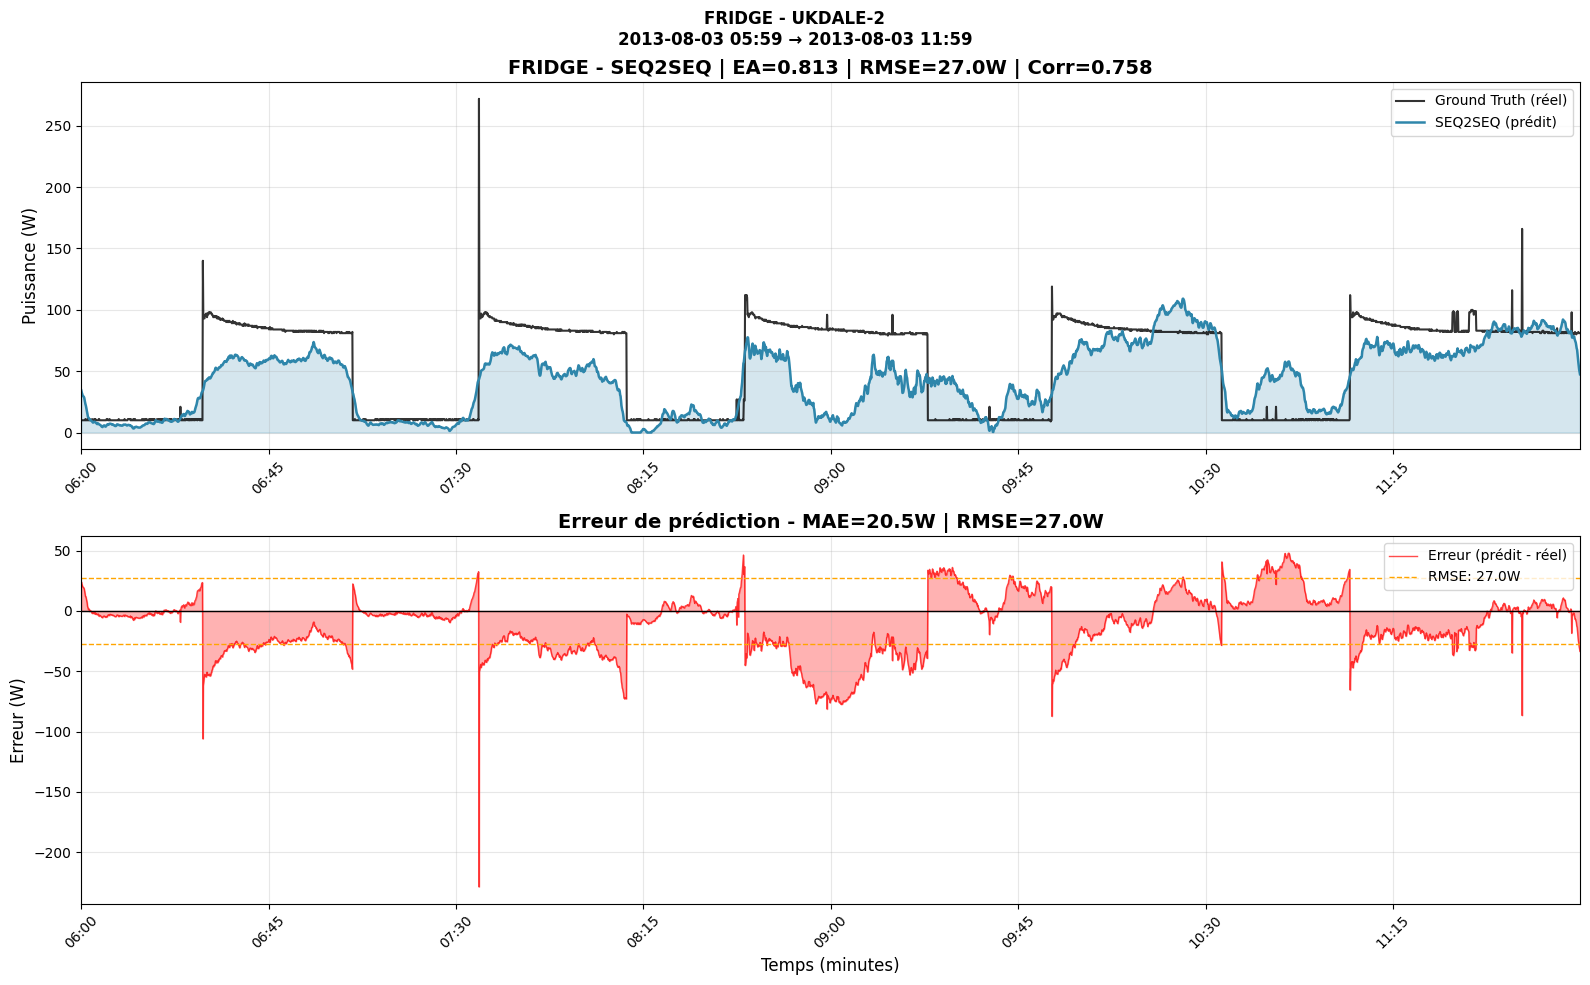


💾 Figure sauvegardée: fridge_seq2seq_custom_20130803_0559.png

📊 MÉTRIQUES sur la période sélectionnée:
   Estimation Accuracy (EA): 0.8125
   RMSE: 27.0 W
   MAE:  20.5 W
   Corrélation: 0.7576

📊 Journée complète: 2013-07-29 17:39 (+24h)

📊 VISUALISATION FRIDGE - Période sélectionnée
   Date début: 2013-07-29 17:39:58.500000+01:00
   Date fin:   2013-07-30 17:39:58.500000+01:00
   Durée:      24 heures
   Modèle:     SEQ2POINT


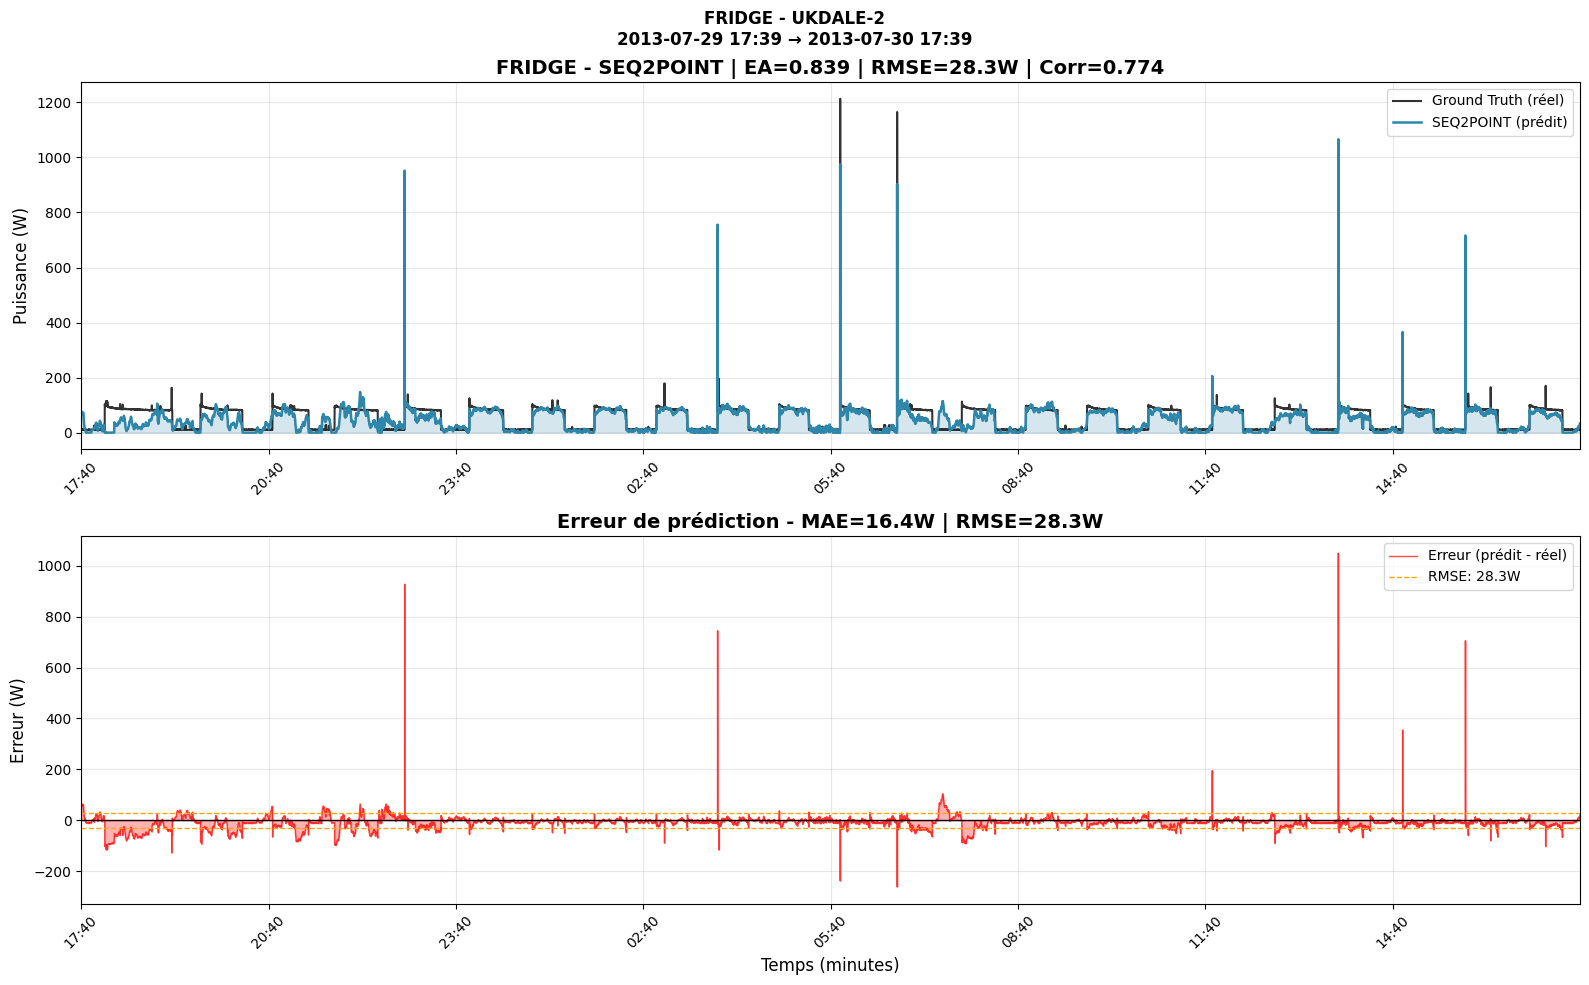


💾 Figure sauvegardée: fridge_seq2point_custom_20130729_1739.png

📊 MÉTRIQUES sur la période sélectionnée:
   Estimation Accuracy (EA): 0.8389
   RMSE: 28.3 W
   MAE:  16.4 W
   Corrélation: 0.7738

📊 VISUALISATION FRIDGE - Période sélectionnée
   Date début: 2013-07-29 17:39:58.500000+01:00
   Date fin:   2013-07-30 17:39:58.500000+01:00
   Durée:      24 heures
   Modèle:     SEQ2SEQ


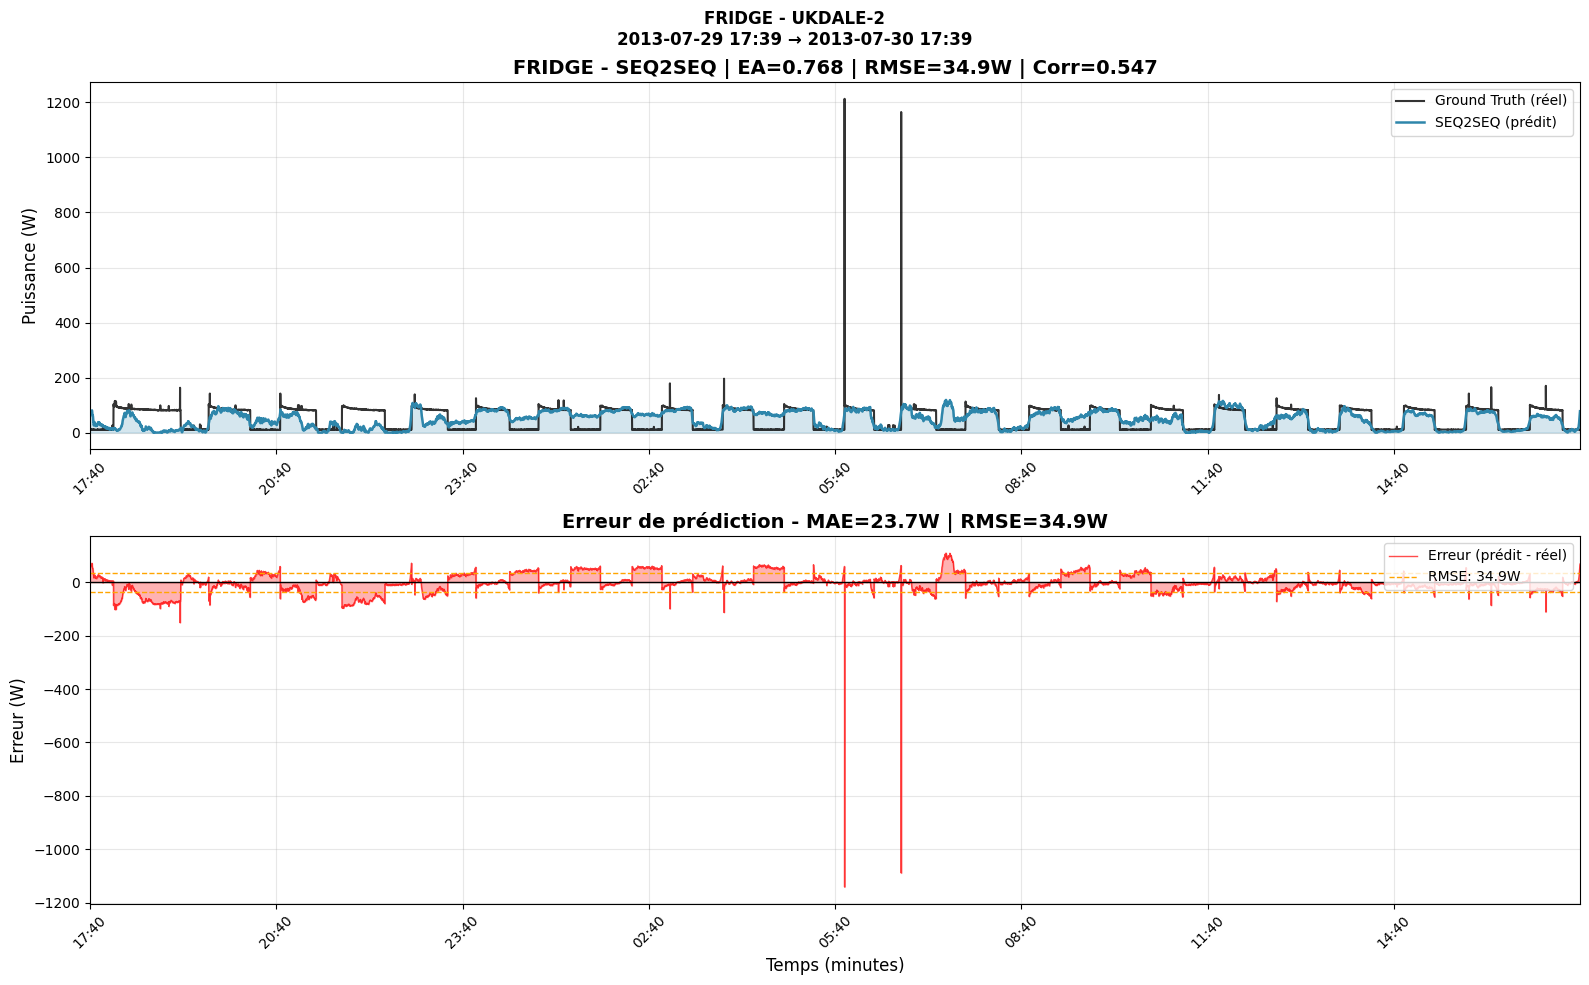


💾 Figure sauvegardée: fridge_seq2seq_custom_20130729_1739.png

📊 MÉTRIQUES sur la période sélectionnée:
   Estimation Accuracy (EA): 0.7676
   RMSE: 34.9 W
   MAE:  23.7 W
   Corrélation: 0.5465


In [18]:
# ============================================================================
# CELL: Visualisation sur des périodes prédéfinies (prêt à l'emploi)
# ============================================================================

if fridge_models and DATA_TEST:
    print("\n" + "="*80)
    print("🎬 VISUALISATIONS FRIDGE - EXEMPLES DE PÉRIODES")
    print("="*80)
    
    # Définir quelques périodes intéressantes
    periods = [
        {"name": "Début des données", "duration_hours": 6, "offset": 0},
        {"name": "Milieu des données", "duration_hours": 6, "offset": 0.5},
        {"name": "Fin des données", "duration_hours": 6, "offset": 0.9},
        {"name": "Journée complète", "duration_hours": 24, "offset": 0.25},
    ]
    
    df_test = DATA_TEST['df']
    df_test.index = pd.to_datetime(df_test.index)
    total_duration = (df_test.index[-1] - df_test.index[0])
    
    for period in periods:
        offset_ratio = period['offset']
        start_offset = total_duration * offset_ratio
        start_date = df_test.index[0] + start_offset
        duration_hours = period['duration_hours']
        
        print(f"\n📊 {period['name']}: {start_date.strftime('%Y-%m-%d %H:%M')} (+{duration_hours}h)")
        
        for model_type, model_info in fridge_models.items():
            if model_info is None:
                continue
            visualize_fridge_custom_period(
                DATA_TEST, model_info, model_type,
                start_date=start_date,
                duration_hours=duration_hours
            )
else:
    print("❌ Modèles ou données non disponibles")


🎯 VISUALISATION MANUELLE - DATES EXTRAITES DES DONNÉES

📅 Fuseau horaire: Europe/London
📅 Période disponible: 2013-07-28 00:00:00+01:00 → 2013-08-03 22:39:54+01:00

📅 Dates valides (extraites des données):
   2013-07-28 00:00:00+01:00
   2013-07-29 17:40:00+01:00
   2013-07-31 11:20:00+01:00
   2013-08-02 05:00:00+01:00
   2013-08-03 21:00:00+01:00

📊 Visualisation avec:
   Date début: 2013-07-29 17:40:00+01:00
   Durée: 6 heures
   Modèle: seq2point

📊 VISUALISATION FRIDGE - Période sélectionnée
   Date début: 2013-07-29 17:40:00+01:00
   Date fin:   2013-07-29 23:40:00+01:00
   Durée:      6 heures
   Modèle:     SEQ2POINT


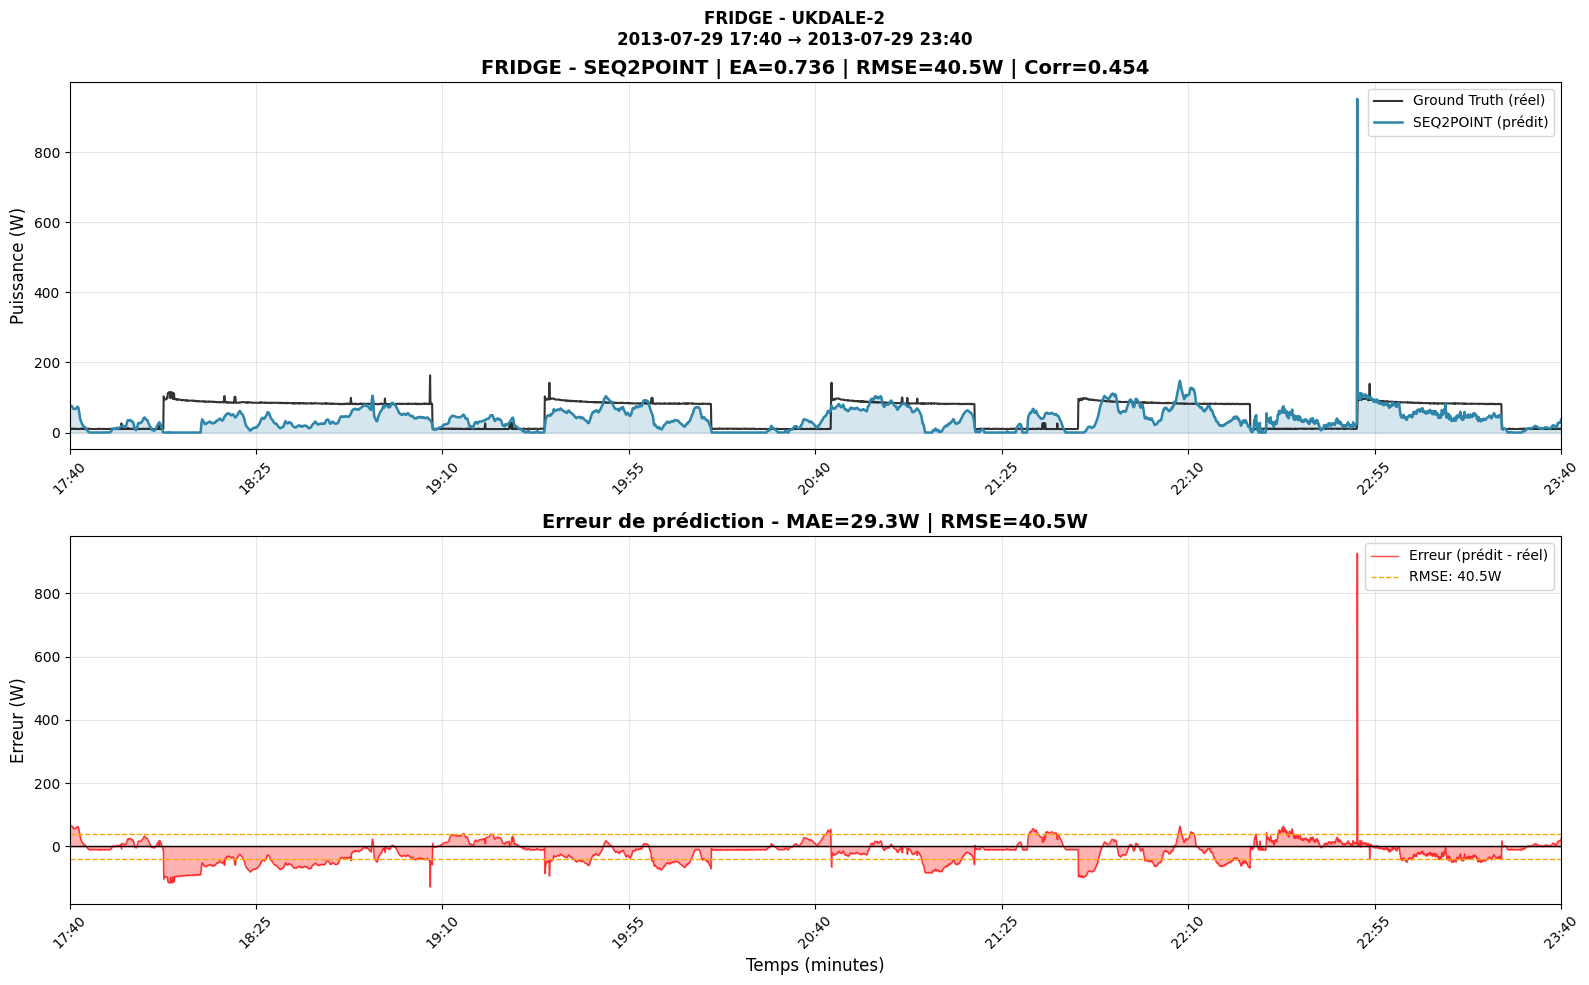


💾 Figure sauvegardée: fridge_seq2point_custom_20130729_1740.png

📊 MÉTRIQUES sur la période sélectionnée:
   Estimation Accuracy (EA): 0.7362
   RMSE: 40.5 W
   MAE:  29.3 W
   Corrélation: 0.4544


In [19]:
# ============================================================================
# CELL: Visualisation MANUELLE - AVEC DATES VALIDES (CORRIGÉE)
# ============================================================================

if fridge_models and DATA_TEST:
    print("\n" + "="*80)
    print("🎯 VISUALISATION MANUELLE - DATES EXTRAITES DES DONNÉES")
    print("="*80)
    
    # Récupérer les dates réelles des données
    df_test = DATA_TEST['df']
    df_test.index = pd.to_datetime(df_test.index)
    tz = df_test.index.tz
    
    print(f"\n📅 Fuseau horaire: {tz}")
    print(f"📅 Période disponible: {df_test.index[0]} → {df_test.index[-1]}")
    
    # Extraire des dates valides (exemples réels)
    valid_dates = []
    for i in [0, len(df_test)//4, len(df_test)//2, 3*len(df_test)//4, -1000]:
        if abs(i) < len(df_test):
            valid_dates.append(df_test.index[i])
    
    print(f"\n📅 Dates valides (extraites des données):")
    for d in valid_dates[:5]:
        print(f"   {d}")
    
    # ============================================================
    # MODIFIEZ CES VALEURS CI-DESSOUS AVEC UNE DATE VALIDE
    # ============================================================
    
    # ⬇️⬇️⬇️ MODIFIEZ ICI (utilisez une des dates ci-dessus) ⬇️⬇️⬇️
    START_DATE = valid_dates[1] if len(valid_dates) > 1 else valid_dates[0]
    DURATION_HOURS = 6
    MODEL_TYPE = 'seq2point'  # 'seq2point' ou 'seq2seq'
    # ⬆️⬆️⬆️ MODIFIEZ ICI ⬆️⬆️⬆️
    
    # ============================================================
    
    print(f"\n📊 Visualisation avec:")
    print(f"   Date début: {START_DATE}")
    print(f"   Durée: {DURATION_HOURS} heures")
    print(f"   Modèle: {MODEL_TYPE}")
    
    for model_type, model_info in fridge_models.items():
        if model_type == MODEL_TYPE and model_info:
            visualize_fridge_custom_period(
                DATA_TEST, model_info, model_type,
                start_date=START_DATE,
                duration_hours=DURATION_HOURS
            )
            break
        
else:
    print("❌ Modèles ou données non disponibles")

In [20]:
# ============================================================================
# CELL: Visualisation FRIDGE - MAISON ET PÉRIODE PERSONNALISABLES
# ============================================================================

def visualize_fridge_any_house(house_key='house_2', model_type='seq2point', 
                               start_date=None, duration_hours=6, 
                               use_trained_model=True):
    """
    Visualise les prédictions du fridge sur n'importe quelle maison et période
    
    PARAMÈTRES:
    - house_key: 'house_1', 'house_2', ou 'house_5'
    - model_type: 'seq2point' ou 'seq2seq'
    - start_date: date de début (ex: '2013-07-30 12:00:00' ou None pour aléatoire)
    - duration_hours: durée en heures (défaut: 6)
    - use_trained_model: True pour utiliser le modèle entraîné, False pour recharger
    """
    
    print("\n" + "="*80)
    print(f"🔍 VISUALISATION FRIDGE - {house_key.upper()}")
    print("="*80)
    
    # 1. Charger les données de la maison
    print(f"\n📂 Chargement des données pour {house_key}...")
    
    try:
        test_data = loader.load_house_data(house_key, mode='test')
        if test_data is None:
            print(f"❌ Pas de données pour {house_key}")
            return None
    except Exception as e:
        print(f"❌ Erreur chargement: {e}")
        return None
    
    df = test_data['df']
    fridge_meter = test_data['fridge_meter']
    
    print(f"✅ Données chargées: {len(df)} points")
    print(f"✅ Compteur fridge: {fridge_meter}")
    
    # 2. Vérifier que le modèle existe
    if fridge_models is None or model_type not in fridge_models:
        print(f"❌ Modèle {model_type} non trouvé!")
        print(f"   Modèles disponibles: {list(fridge_models.keys()) if fridge_models else 'Aucun'}")
        return None
    
    model_info = fridge_models[model_type]
    if model_info is None:
        print(f"❌ Modèle {model_type} non entraîné!")
        return None
    
    print(f"✅ Modèle {model_type} chargé (best epoch: {model_info['best_epoch']})")
    
    # 3. Déterminer la période
    df.index = pd.to_datetime(df.index)
    tz = df.index.tz
    
    if start_date is None:
        # Période aléatoire au milieu des données
        mid_point = len(df) // 2
        start_date = df.index[mid_point]
        print(f"\n🎲 Période aléatoire générée: {start_date}")
    else:
        if isinstance(start_date, str):
            start_date = pd.to_datetime(start_date)
        if start_date.tz is None and tz is not None:
            start_date = start_date.tz_localize(tz)
        elif start_date.tz is not None and tz is not None:
            start_date = start_date.tz_convert(tz)
    
    end_date = start_date + pd.Timedelta(hours=duration_hours)
    
    print(f"\n📅 Période sélectionnée:")
    print(f"   Début: {start_date}")
    print(f"   Fin:   {end_date}")
    print(f"   Durée: {duration_hours} heures")
    
    # 4. Filtrer les données
    mask = (df.index >= start_date) & (df.index <= end_date)
    df_period = df.loc[mask]
    
    if len(df_period) == 0:
        print(f"\n❌ Aucune donnée sur cette période!")
        print(f"   Période disponible: {df.index[0]} → {df.index[-1]}")
        
        # Proposer des périodes valides
        print(f"\n💡 Périodes valides suggérées:")
        for i, idx in enumerate([0, len(df)//4, len(df)//2, 3*len(df)//4, -1000]):
            if abs(idx) < len(df):
                print(f"   - {df.index[idx]} (durée {duration_hours}h)")
        return None
    
    # 5. Extraire les données
    true_vals = df_period[fridge_meter].values
    mains_vals = df_period[test_data['monitored_meters']].sum(axis=1).values
    
    # 6. Prédiction
    print(f"\n🔄 Inférence en cours...")
    mains_s = pd.Series(mains_vals)
    pred = predict_fridge(mains_s, model_info, model_type)
    pred = np.clip(pred, 0, None)
    
    # 7. Métriques
    min_len = min(len(true_vals), len(pred))
    true_vals = true_vals[:min_len]
    pred = pred[:min_len]
    metrics = NILMMetrics.compute_all(true_vals, pred)
    
    # 8. Graphique
    time_min = np.arange(len(true_vals)) * 6 / 60
    
    fig, axes = plt.subplots(2, 1, figsize=(16, 10))
    
    # Graphique 1: Comparaison
    ax1 = axes[0]
    ax1.plot(time_min, true_vals, color='black', lw=1.5, alpha=0.8, label='Ground Truth (réel)')
    ax1.plot(time_min, pred, color='#2E86AB', lw=1.8, label=f'{model_type.upper()} (prédit)')
    ax1.fill_between(time_min, 0, pred, alpha=0.2, color='#2E86AB')
    ax1.set_ylabel('Puissance (W)', fontsize=12)
    ax1.set_title(f'FRIDGE - {house_key} | {model_type.upper()} | EA={metrics["ea"]:.3f} | RMSE={metrics["rmse"]:.1f}W | Corr={metrics["corr"]:.3f}', 
                  fontsize=14, fontweight='bold')
    ax1.legend(loc='upper right')
    ax1.grid(True, alpha=0.3)
    ax1.set_xlim([0, time_min[-1]])
    
    # Graphique 2: Erreur
    ax2 = axes[1]
    error = pred - true_vals
    ax2.plot(time_min, error, color='red', lw=1, alpha=0.7, label='Erreur')
    ax2.fill_between(time_min, 0, error, alpha=0.3, color='red')
    ax2.axhline(0, color='black', ls='-', lw=1)
    ax2.axhline(metrics['rmse'], color='orange', ls='--', lw=1, label=f'RMSE: {metrics["rmse"]:.1f}W')
    ax2.axhline(-metrics['rmse'], color='orange', ls='--', lw=1)
    ax2.set_xlabel('Temps (minutes)', fontsize=12)
    ax2.set_ylabel('Erreur (W)', fontsize=12)
    ax2.set_title(f'Erreur - MAE={metrics["mae"]:.1f}W | RMSE={metrics["rmse"]:.1f}W', fontweight='bold')
    ax2.legend(loc='upper right')
    ax2.grid(True, alpha=0.3)
    ax2.set_xlim([0, time_min[-1]])
    
    # Dates sur l'axe
    dates = df_period.index[:min_len]
    step = max(1, len(dates) // 8)
    xticks_pos = np.arange(0, len(dates), step) * 6 / 60
    xticks_labels = [dates[i].strftime('%H:%M') for i in range(0, len(dates), step)]
    ax1.set_xticks(xticks_pos)
    ax1.set_xticklabels(xticks_labels, rotation=45)
    ax2.set_xticks(xticks_pos)
    ax2.set_xticklabels(xticks_labels, rotation=45)
    
    plt.suptitle(f'FRIDGE - {test_data["name"]}\n{start_date.strftime("%Y-%m-%d %H:%M")} → {end_date.strftime("%Y-%m-%d %H:%M")}',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    
    # Sauvegarde
    fname = f'fridge_{house_key}_{model_type}_{start_date.strftime("%Y%m%d_%H%M")}.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"\n💾 Figure: {fname}")
    print(f"\n📊 MÉTRIQUES:")
    print(f"   EA:   {metrics['ea']:.4f}")
    print(f"   RMSE: {metrics['rmse']:.1f} W")
    print(f"   MAE:  {metrics['mae']:.1f} W")
    print(f"   Corr: {metrics['corr']:.4f}")
    
    return metrics


🎯 TESTS SUR DIFFÉRENTES MAISONS ET PÉRIODES

🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢

🔍 VISUALISATION FRIDGE - HOUSE_2

📂 Chargement des données pour house_2...

TEST: UKDALE-2
Période: 2013-07-28 → 2013-08-11
FRIDGE compteur: meter14
✅ meter14: 1,687,285 points
✅ 20 compteurs chargés
Grille: 201,601 points

📊 FRIDGE (meter14) - test:
   Max: 1295 W
   Moy: 33.9 W
   Points: 201,601
✅ Données chargées: 201601 points
✅ Compteur fridge: meter14
✅ Modèle seq2point chargé (best epoch: 45)

🎲 Période aléatoire générée: 2013-08-04 00:00:00+01:00

📅 Période sélectionnée:
   Début: 2013-08-04 00:00:00+01:00
   Fin:   2013-08-04 06:00:00+01:00
   Durée: 6 heures

🔄 Inférence en cours...


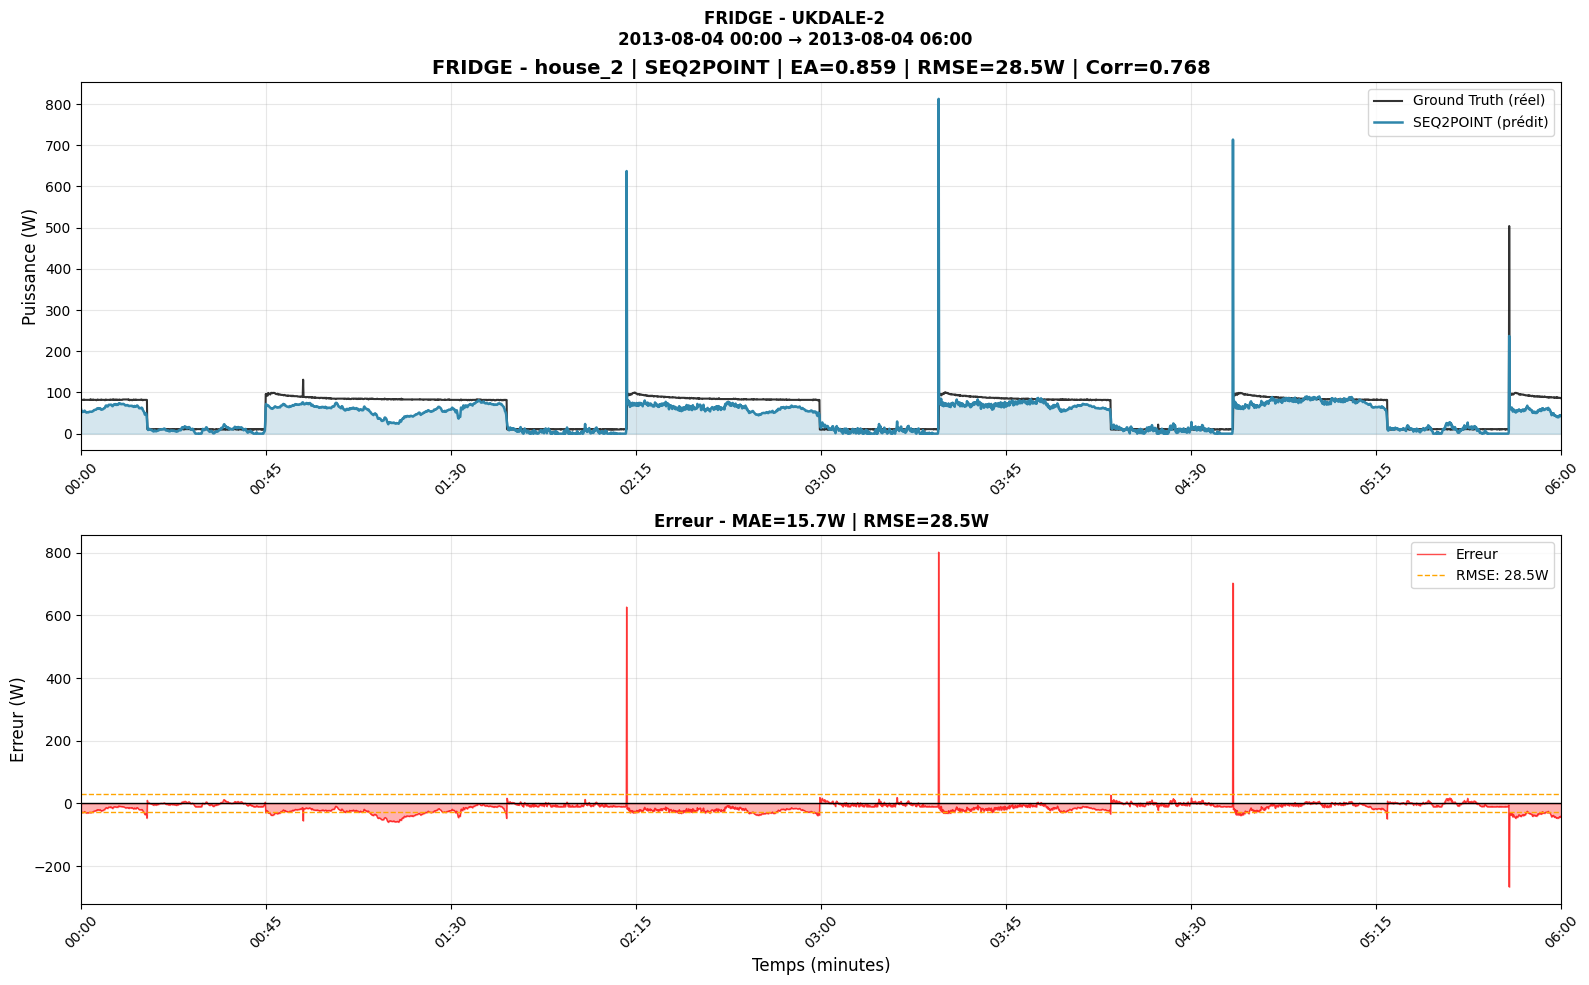


💾 Figure: fridge_house_2_seq2point_20130804_0000.png

📊 MÉTRIQUES:
   EA:   0.8586
   RMSE: 28.5 W
   MAE:  15.7 W
   Corr: 0.7677

🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢

🔍 VISUALISATION FRIDGE - HOUSE_2

📂 Chargement des données pour house_2...

TEST: UKDALE-2
Période: 2013-07-28 → 2013-08-11
FRIDGE compteur: meter14
✅ meter14: 1,687,285 points
✅ 20 compteurs chargés
Grille: 201,601 points

📊 FRIDGE (meter14) - test:
   Max: 1295 W
   Moy: 33.9 W
   Points: 201,601
✅ Données chargées: 201601 points
✅ Compteur fridge: meter14
✅ Modèle seq2seq chargé (best epoch: 43)

🎲 Période aléatoire générée: 2013-08-04 00:00:00+01:00

📅 Période sélectionnée:
   Début: 2013-08-04 00:00:00+01:00
   Fin:   2013-08-04 06:00:00+01:00
   Durée: 6 heures

🔄 Inférence en cours...


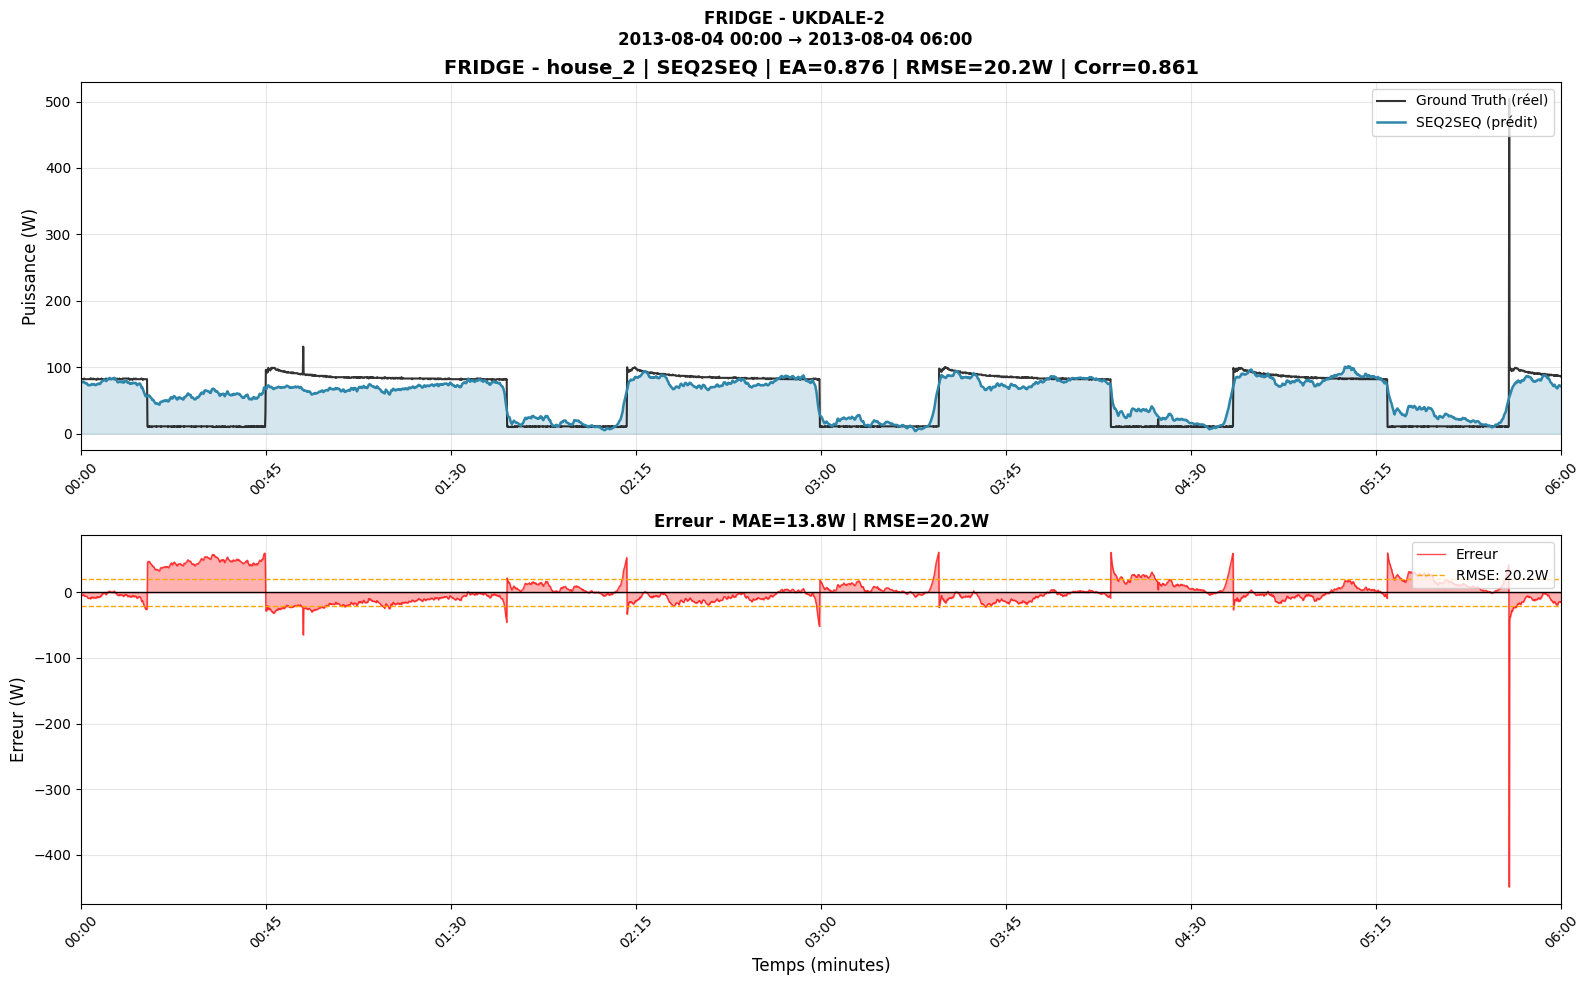


💾 Figure: fridge_house_2_seq2seq_20130804_0000.png

📊 MÉTRIQUES:
   EA:   0.8758
   RMSE: 20.2 W
   MAE:  13.8 W
   Corr: 0.8608

🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢

🔍 VISUALISATION FRIDGE - HOUSE_1

📂 Chargement des données pour house_1...

TEST: UKDALE-1
Période: 2014-04-01 → 2014-05-01
FRIDGE compteur: meter12
✅ meter12: 19,381,298 points
✅ 29 compteurs chargés
⚠️ Pas de données dans la période sélectionnée!
❌ Pas de données pour house_1

🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢

🔍 VISUALISATION FRIDGE - HOUSE_5

📂 Chargement des données pour house_5...
❌ Erreur chargement: Maison house_5 non trouvée


In [21]:
# ============================================================================
# CELL: TESTS RAPIDES - Différentes maisons et périodes
# ============================================================================

if fridge_models and DATA_TEST:
    print("\n" + "="*80)
    print("🎯 TESTS SUR DIFFÉRENTES MAISONS ET PÉRIODES")
    print("="*80)
    
    # ============================================================
    # MODIFIEZ CES VALEURS POUR TESTER DIFFÉRENTES CONFIGURATIONS
    # ============================================================
    
    # Configuration du test
    TEST_CONFIGS = [
        # (maison, modèle, durée_heures, date_début)
        ('house_2', 'seq2point', 6, None),      # Maison 2, aléatoire
        ('house_2', 'seq2seq', 6, None),        # Maison 2, aléatoire
        ('house_1', 'seq2point', 4, None),      # Maison 1 (entraînement)
        ('house_5', 'seq2point', 8, None),      # Maison 5 (si disponible)
    ]
    
    # ============================================================
    
    for house_key, model_type, duration, start_date in TEST_CONFIGS:
        print("\n" + "🟢"*40)
        visualize_fridge_any_house(
            house_key=house_key,
            model_type=model_type,
            start_date=start_date,
            duration_hours=duration
        )
        
else:
    print("❌ Modèles non disponibles. Exécutez d'abord l'entraînement.")